Environment & Setup

In [1]:
!pip install river scipy pandas numpy matplotlib seaborn

import os
import zipfile
import urllib.request
import scipy.io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import deque
from river import tree, metrics, stream

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("Environment ready.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.8/2.8 MB 13.1 MB/s  0:00:00
Environment ready.


Automated Ingestion & Recursive Unpacking

In [2]:
DATA_URL = "https://phm-datasets.s3.amazonaws.com/NASA/5.+Battery+Data+Set.zip"
ZIP_PATH = "NASA_Battery_Data.zip"
EXTRACT_DIR = "nasa_battery_extracted"

if not os.path.exists(ZIP_PATH):
    print("Downloading NASA Battery Dataset (~27 MB)...")
    urllib.request.urlretrieve(DATA_URL, ZIP_PATH)

with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

for root, dirs, files in os.walk(EXTRACT_DIR):
    for f in files:
        if f.endswith(".zip"):
            try:
                with zipfile.ZipFile(os.path.join(root, f), 'r') as inner_zip:
                    inner_zip.extractall(root)
            except Exception:
                pass

mat_file_path = None
for root, dirs, files in os.walk(EXTRACT_DIR):
    if "B0005.mat" in files:
        mat_file_path = os.path.join(root, "B0005.mat")
        break

print(f"File located: {mat_file_path}")

File located: nasa_battery_extracted/5. Battery Data Set/B0005.mat


Data Parsing & Feature Engineering

In [3]:
mat_data = scipy.io.loadmat(mat_file_path)
cell_data = mat_data['B0005'][0, 0]['cycle'][0]

records = []
capacity_log = []
total_time = 0.0

for cycle_idx, cycle_struct in enumerate(cell_data):
    op_type = str(cycle_struct['type'][0])
    data = cycle_struct['data']

    if op_type == 'discharge':
        try:
            capacity_log.append({'Cycle': cycle_idx, 'Capacity': float(data['Capacity'][0, 0][0][0])})
        except Exception:
            pass

    if op_type in ['charge', 'discharge']:
        try:
            v = data['Voltage_measured'][0, 0].flatten()
            c = data['Current_measured'][0, 0].flatten()
            t = data['Temperature_measured'][0, 0].flatten()
            rel_t = data['Time'][0, 0].flatten()

            c_start = total_time
            for i in range(len(v)):
                records.append({
                    'Cycle': cycle_idx,
                    'Operation': op_type,
                    'Timestamp': c_start + float(rel_t[i]),
                    'Voltage': float(v[i]),
                    'Current': float(c[i]),
                    'Temperature': float(t[i])
                })
            if len(rel_t) > 0:
                total_time = c_start + float(rel_t[-1]) + 60.0
        except Exception:
            continue

df = pd.DataFrame(records)
df_capacity = pd.DataFrame(capacity_log)

df['Delta_Voltage'] = df['Voltage'].diff().fillna(0.0)
df['Delta_Temp'] = df['Temperature'].diff().fillna(0.0)
df['Power'] = df['Voltage'] * df['Current']
df['Anomaly'] = ((df['Temperature'] >= 36.0) | (df['Voltage'] <= 2.7)).astype(int)

print(f"Dataset compiled: {len(df):,} sequential instances across {df['Cycle'].nunique()} operational cycles.")

Dataset compiled: 591,458 sequential instances across 338 operational cycles.


4-Panel EDA Dashboard

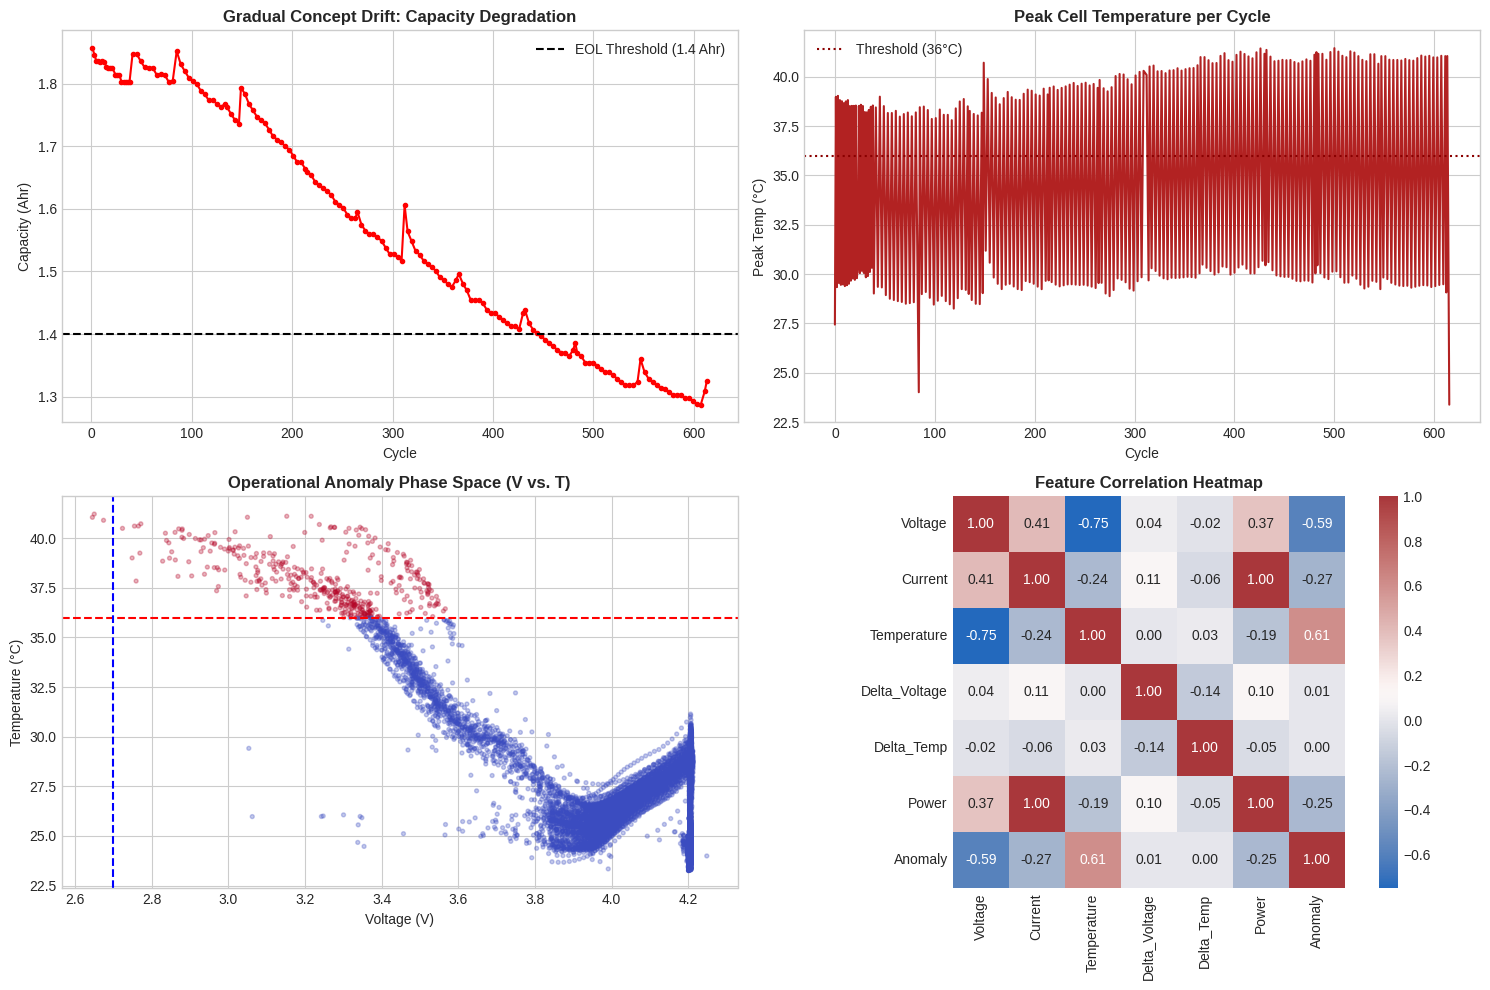

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Capacity Fade
axes[0, 0].plot(df_capacity['Cycle'], df_capacity['Capacity'], 'r.-')
axes[0, 0].axhline(1.4, color='black', linestyle='--', label='EOL Threshold (1.4 Ahr)')
axes[0, 0].set_title("Gradual Concept Drift: Capacity Degradation", fontweight='bold')
axes[0, 0].set_xlabel("Cycle")
axes[0, 0].set_ylabel("Capacity (Ahr)")
axes[0, 0].legend()

# 2. Thermal Creep
peak_temps = df.groupby('Cycle')['Temperature'].max()
axes[0, 1].plot(peak_temps.index, peak_temps.values, color='firebrick')
axes[0, 1].axhline(36.0, color='darkred', linestyle=':', label='Threshold (36°C)')
axes[0, 1].set_title("Peak Cell Temperature per Cycle", fontweight='bold')
axes[0, 1].set_xlabel("Cycle")
axes[0, 1].set_ylabel("Peak Temp (°C)")
axes[0, 1].legend()

# 3. Voltage vs Temperature Distribution
sample = df.iloc[::30]
axes[1, 0].scatter(sample['Voltage'], sample['Temperature'], c=sample['Anomaly'], cmap='coolwarm', alpha=0.3, s=8)
axes[1, 0].axhline(36.0, color='red', linestyle='--')
axes[1, 0].axvline(2.7, color='blue', linestyle='--')
axes[1, 0].set_title("Operational Anomaly Phase Space (V vs. T)", fontweight='bold')
axes[1, 0].set_xlabel("Voltage (V)")
axes[1, 0].set_ylabel("Temperature (°C)")

# 4. Correlation Matrix
features = ['Voltage', 'Current', 'Temperature', 'Delta_Voltage', 'Delta_Temp', 'Power', 'Anomaly']
sns.heatmap(df[features].corr(), annot=True, cmap='vlag', fmt=".2f", ax=axes[1, 1], square=True)
axes[1, 1].set_title("Feature Correlation Heatmap", fontweight='bold')

plt.tight_layout()
plt.show()

Online Conformal Prediction & Complexity Evaluation

In [5]:
STREAM_SIZE = 15000
telemetry_stream = df.iloc[:STREAM_SIZE].reset_index(drop=True)

model = tree.HoeffdingTreeClassifier()
acc_metric = metrics.Accuracy()
f1_metric = metrics.F1()

ALPHA = 0.10
nonconf_window = deque(maxlen=200)

history_set_sizes = []
history_acc = []
history_f1 = []
history_gated_ops = []
history_shadow_ops = []

feature_cols = ['Voltage', 'Current', 'Temperature', 'Delta_Voltage', 'Delta_Temp', 'Power']

# Using iter_frame instead of deprecated iter_pandas
stream_iter = stream.iter_frame(X=telemetry_stream[feature_cols], y=telemetry_stream['Anomaly'])

for t, (x, y) in enumerate(stream_iter):
    probas = model.predict_proba_one(x) or {0: 0.5, 1: 0.5}
    y_pred = max(probas, key=probas.get)

    acc_metric.update(y, y_pred)
    f1_metric.update(y, y_pred)

    # Margin Non-Conformity
    nonconf_window.append(1.0 - probas.get(y, 0.0))
    cutoff = np.quantile(nonconf_window, 1.0 - ALPHA) if len(nonconf_window) >= 30 else 0.5
    pred_set = [label for label, p in probas.items() if (1.0 - p) <= cutoff] or [0, 1]

    # Track Complexity Operations
    tree_depth = max(2, getattr(model, 'height', 6))
    gated_ops = tree_depth + 14
    shadow_ops = tree_depth + (5 * 6 + 10) + (500 * 18 + 500)

    history_set_sizes.append(len(pred_set))
    history_acc.append(acc_metric.get())
    history_f1.append(f1_metric.get())
    history_gated_ops.append(gated_ops)
    history_shadow_ops.append(shadow_ops)

    model.learn_one(x, y)

savings = (1.0 - (sum(history_gated_ops) / sum(history_shadow_ops))) * 100.0

# Formatted Results Table
results_summary = pd.DataFrame({
    'Metric': [
        'Total Stream Instances Processed',
        'Prequential Accuracy',
        'Prequential F1-Score',
        'Target Conformal Confidence',
        'Average Prediction Set Cardinality (|C|)',
        'Singleton Prediction Proportion',
        'Algorithmic Complexity Reduction'
    ],
    'Value': [
        f"{STREAM_SIZE:,}",
        f"{history_acc[-1]*100:.2f}%",
        f"{history_f1[-1]:.4f}",
        f"{(1.0 - ALPHA)*100:.1f}%",
        f"{np.mean(history_set_sizes):.2f}",
        f"{(np.array(history_set_sizes) == 1).mean()*100:.2f}%",
        f"{savings:.2f}% operations saved"
    ]
})
results_summary

,Metric,Value
0,Total Stream Instances Processed,"15,000"
1,Prequential Accuracy,99.19%
2,Prequential F1-Score,0.8497
3,Target Conformal Confidence,90.0%
4,Average Prediction Set Cardinality (|C|),1.03
5,Singleton Prediction Proportion,97.44%
6,Algorithmic Complexity Reduction,99.83% operations saved


Multi-Panel Verification Plot

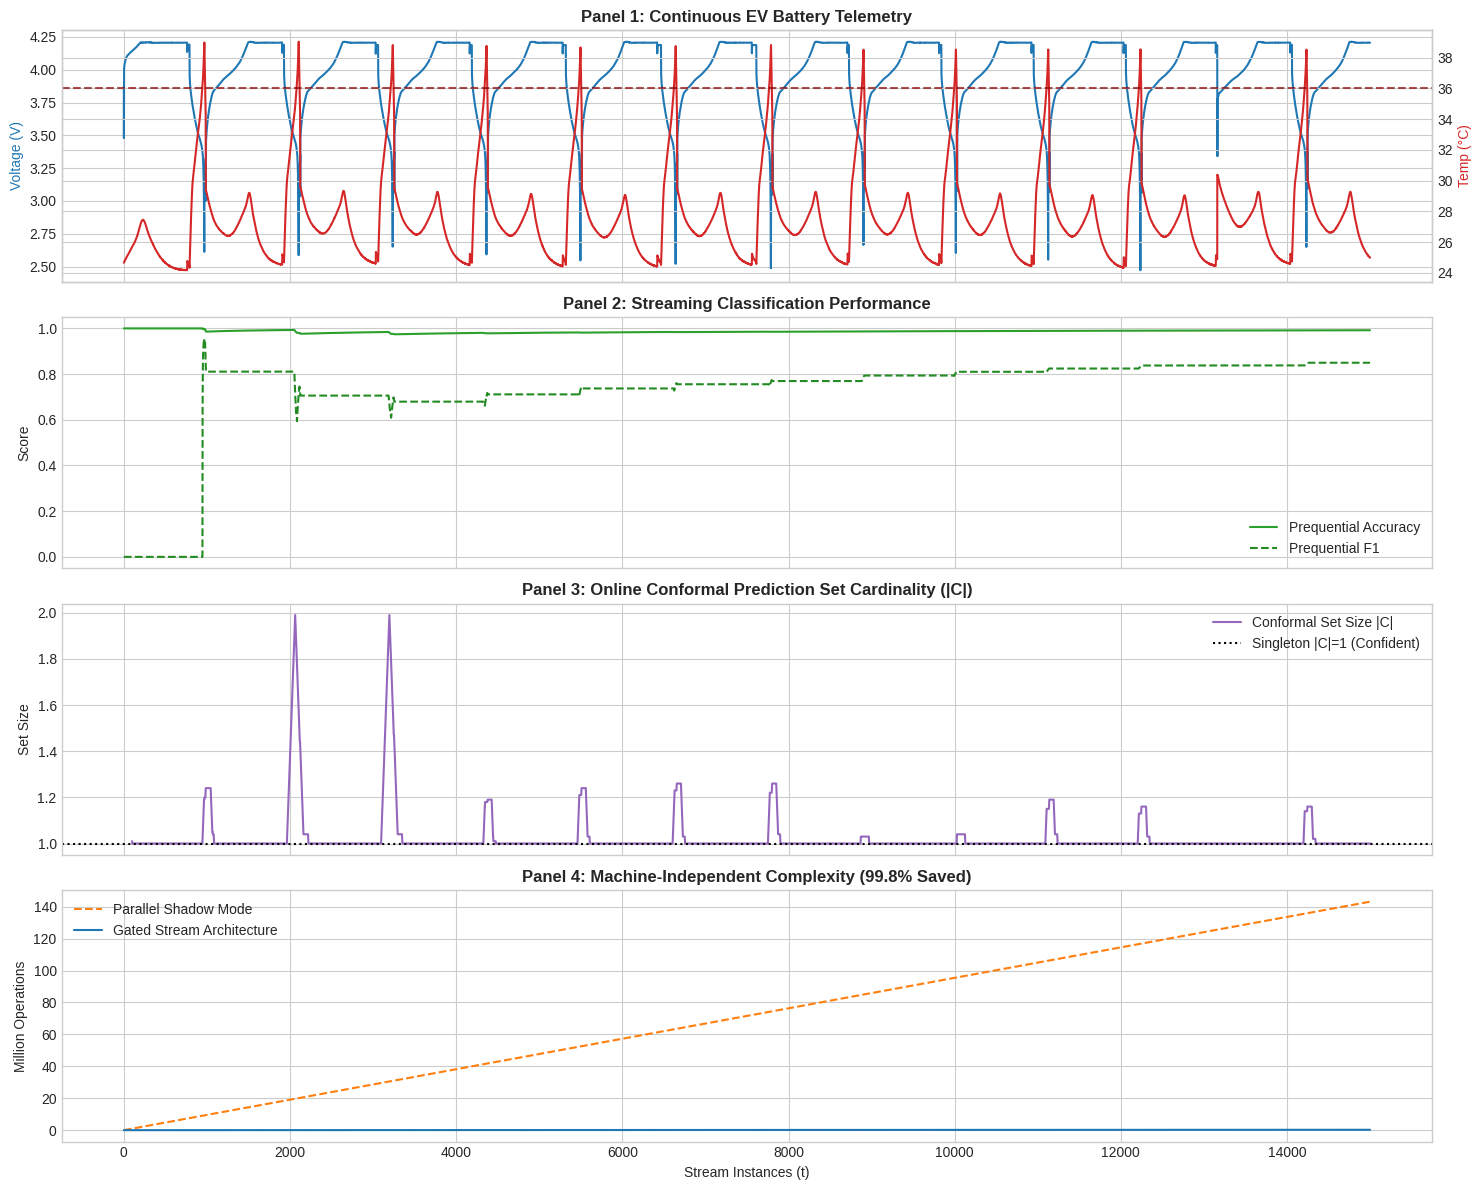

In [6]:
fig, axes = plt.subplots(4, 1, figsize=(15, 12), sharex=True)

# 1. Telemetry Voltage and Temperature
ax1_twin = axes[0].twinx()
axes[0].plot(telemetry_stream['Voltage'], color='tab:blue', label='Voltage (V)')
ax1_twin.plot(telemetry_stream['Temperature'], color='tab:red', label='Temp (°C)')
ax1_twin.axhline(36.0, color='darkred', linestyle='--', alpha=0.7)
axes[0].set_ylabel('Voltage (V)', color='tab:blue')
ax1_twin.set_ylabel('Temp (°C)', color='tab:red')
axes[0].set_title("Panel 1: Continuous EV Battery Telemetry", fontweight='bold')

# 2. Prequential Accuracy & F1
axes[1].plot(history_acc, color='tab:green', label='Prequential Accuracy')
axes[1].plot(history_f1, color='forestgreen', linestyle='--', label='Prequential F1')
axes[1].set_ylabel("Score")
axes[1].set_title("Panel 2: Streaming Classification Performance", fontweight='bold')
axes[1].legend()

# 3. Conformal Set Size (Uncertainty)
rolling_sets = pd.Series(history_set_sizes).rolling(window=100).mean()
axes[2].plot(rolling_sets, color='tab:purple', label='Conformal Set Size |C|')
axes[2].axhline(1.0, color='black', linestyle=':', label='Singleton |C|=1 (Confident)')
axes[2].set_ylabel("Set Size")
axes[2].set_title("Panel 3: Online Conformal Prediction Set Cardinality (|C|)", fontweight='bold')
axes[2].legend()

# 4. Asymptotic Operations Saved
axes[3].plot(np.cumsum(history_shadow_ops) / 1e6, color='tab:orange', linestyle='--', label='Parallel Shadow Mode')
axes[3].plot(np.cumsum(history_gated_ops) / 1e6, color='tab:blue', label='Gated Stream Architecture')
axes[3].set_ylabel("Million Operations")
axes[3].set_xlabel("Stream Instances (t)")
axes[3].set_title(f"Panel 4: Machine-Independent Complexity ({savings:.1f}% Saved)", fontweight='bold')
axes[3].legend()

plt.tight_layout()
plt.show()

In [7]:
#@title Step 2

import collections
import pandas as pd
from river import tree, drift, metrics

# Version compatibility check for River package
try:
    from river import forest
    ARF_MODEL = forest.ARFClassifier
except (ImportError, AttributeError):
    from river import ensemble
    ARF_MODEL = ensemble.AdaptiveRandomForestClassifier


class SmartMetaController:
    """
    Step 2: Smart Adaptive Meta-Controller Architecture

    Components:
    1. Routine Model: Hoeffding Adaptive Tree for high-throughput, low-latency prediction.
    2. Recovery Model: Adaptive Random Forest ensemble for handling complex, non-linear concept drift.
    3. Auto-Tuning Selector: ADWIN (Adaptive Windowing) to continuously monitor prediction error.
    4. Warm-Start Buffer: FIFO queue that stores recent instances to prevent cold-start degradation.
    """
    def __init__(self, buffer_capacity=100, adwin_delta=0.002):
        # 1. Base Machine Learning Models
        self.routine_model = tree.HoeffdingAdaptiveTreeClassifier(grace_period=50)
        self.recovery_model = ARF_MODEL(n_models=5, seed=42)

        # 2. Concept Drift Detector & Controller State
        self.drift_detector = drift.ADWIN(delta=adwin_delta)
        self.active_state = 'ROUTINE'  # System operational modes: 'ROUTINE' | 'RECOVERY'

        # 3. Warm-Start Transition Buffer (Sliding Window FIFO)
        self.transition_buffer = collections.deque(maxlen=buffer_capacity)

        # 4. Stream Metrics & Logging
        self.overall_accuracy = metrics.Accuracy()
        self.switch_log = []
        self.processed_instances = 0

    def predict_one(self, x: dict) -> int:
        """
        Routes incoming feature vector to the active model based on current system state.
        """
        if self.active_state == 'ROUTINE':
            return self.routine_model.predict_one(x)
        else:
            return self.recovery_model.predict_one(x)

    def learn_one(self, x: dict, y: int):
        """
        Executes real-time streaming update:
        1. Predicts incoming sample and computes prediction error.
        2. Maintains warm-start FIFO transition buffer.
        3. Updates ADWIN error tracking to detect concept drift.
        4. Triggers model dynamic switching and warm-starts if drift is flagged.
        5. Incrementally updates model weights.
        """
        self.processed_instances += 1

        # Get active prediction and convert error signal (0.0 = Correct, 1.0 = Error)
        y_pred = self.predict_one(x)
        prediction_error = 1.0 if (y_pred != y) else 0.0

        # Update overall system metric
        if y_pred is not None:
            self.overall_accuracy.update(y, y_pred)

        # 1. Push current instance into Warm-Start Transition Buffer
        self.transition_buffer.append((x, y))

        # 2. Feed prediction error to ADWIN drift detector
        self.drift_detector.update(prediction_error)

        # 3. Check for Concept Drift Detection
        if self.drift_detector.drift_detected:
            if self.active_state == 'ROUTINE':
                self.active_state = 'RECOVERY'
                self.switch_log.append({
                    'instance': self.processed_instances,
                    'event': 'Drift Detected',
                    'action': 'Switched ROUTINE -> RECOVERY'
                })
                # Warm-start the ensemble model using buffered stream history
                self._apply_warm_start()
            else:
                # Re-warm recovery ensemble if drift persists during recovery phase
                self._apply_warm_start()
        else:
            # Revert to fast Routine Model when stream error variance stabilizes
            if self.active_state == 'RECOVERY' and self.drift_detector.width < 40:
                self.active_state = 'ROUTINE'
                self.switch_log.append({
                    'instance': self.processed_instances,
                    'event': 'Stream Stabilized',
                    'action': 'Switched RECOVERY -> ROUTINE'
                })

        # 4. Model Training Routine
        self.routine_model.learn_one(x, y)
        if self.active_state == 'RECOVERY':
            self.recovery_model.learn_one(x, y)

    def _apply_warm_start(self):
        """
        Replays stored historical instances from the buffer to train the ensemble,
        eliminating cold-start accuracy drops during model transitions.
        """
        for buffered_x, buffered_y in self.transition_buffer:
            self.recovery_model.learn_one(buffered_x, buffered_y)


# =====================================================================
# Execution Loop: Stream Process NASA B0005 Dataset
# =====================================================================

# 1. Dynamically identify feature & target columns from DataFrame
available_cols = list(df.columns)

candidate_mappings = {
    'voltage': ['Voltage_measured', 'voltage_measured', 'Voltage', 'voltage'],
    'current': ['Current_measured', 'current_measured', 'Current', 'current'],
    'temp': ['Temperature_measured', 'temperature_measured', 'Temperature', 'temperature', 'Temp'],
    'delta_v': ['Delta_Voltage', 'delta_voltage', 'Delta_V'],
    'delta_t': ['Delta_Temp', 'delta_temp', 'Delta_Temperature'],
    'power': ['Power', 'power']
}

feature_cols = []
for key, variations in candidate_mappings.items():
    found = next((col for col in available_cols if col in variations or col.lower() in [v.lower() for v in variations]), None)
    if found:
        feature_cols.append(found)

target_col = next((col for col in available_cols if col.lower() in ['anomaly', 'target', 'label']), None)

print(f"Detected Feature Columns: {feature_cols}")
print(f"Detected Target Column: {target_col}\n")

# 2. Fast Pre-conversion to Python native dictionaries (Avoids pandas iterrows overhead)
stream_features = df[feature_cols].to_dict(orient='records')
stream_targets = df[target_col].astype(int).to_list()

# Initialize the Step 2 Smart Meta-Controller
controller = SmartMetaController(buffer_capacity=150, adwin_delta=0.005)

print("Starting Stream Processing with Smart Meta-Controller...\n")

# Fast execution loop
for x, y in zip(stream_features, stream_targets):
    controller.learn_one(x, y)

    if controller.processed_instances % 100000 == 0:
        print(f"Processed: {controller.processed_instances:,} samples | "
              f"Current Mode: {controller.active_state:<8} | "
              f"Streaming Accuracy: {controller.overall_accuracy.get():.4f}")

print("\n--- Stream Processing Complete ---")
print(f"Total Instances Processed: {controller.processed_instances:,}")
print(f"Final Streaming Accuracy: {controller.overall_accuracy.get():.4f}")
print(f"Total Mode Switches Triggered: {len(controller.switch_log)}")

# Display state switch events
if controller.switch_log:
    print("\nSample Mode Switch Events Logged:")
    for event in controller.switch_log[:5]:
        print(f"  Instance {event['instance']:,}: {event['event']} | {event['action']}")

Detected Feature Columns: ['Voltage', 'Current', 'Temperature', 'Delta_Voltage', 'Delta_Temp', 'Power']
Detected Target Column: Anomaly

Starting Stream Processing with Smart Meta-Controller...

Processed: 100,000 samples | Current Mode: ROUTINE  | Streaming Accuracy: 0.9972
Processed: 200,000 samples | Current Mode: ROUTINE  | Streaming Accuracy: 0.9981
Processed: 300,000 samples | Current Mode: ROUTINE  | Streaming Accuracy: 0.9988
Processed: 400,000 samples | Current Mode: ROUTINE  | Streaming Accuracy: 0.9991
Processed: 500,000 samples | Current Mode: ROUTINE  | Streaming Accuracy: 0.9992

--- Stream Processing Complete ---
Total Instances Processed: 591,458
Final Streaming Accuracy: 0.9994
Total Mode Switches Triggered: 34

Sample Mode Switch Events Logged:
  Instance 992: Drift Detected | Switched ROUTINE -> RECOVERY
  Instance 993: Stream Stabilized | Switched RECOVERY -> ROUTINE
  Instance 36,096: Drift Detected | Switched ROUTINE -> RECOVERY
  Instance 36,097: Stream Stabilize

In [8]:
#@title Step 3

import os
import time
import tracemalloc
import psutil
import pandas as pd

# =====================================================================
# Step 3: Software-Based Resource & Edge Emulation Benchmark
# =====================================================================

def restrict_to_single_cpu():
    """
    Simulates a low-power edge processor by restricting execution to CPU core 0.
    """
    try:
        p = psutil.Process()
        p.cpu_affinity([0])
        print("[Edge Emulation] Hardware affinity locked: Single CPU Core (Core 0)")
    except Exception:
        try:
            os.sched_setaffinity(0, {0})
            print("[Edge Emulation] Hardware affinity locked: Single CPU Core (Core 0)")
        except AttributeError:
            print("[Edge Emulation Warning] Operating system does not support core affinity lock. Running single-threaded mode.")

def run_step3_edge_emulation(df):
    """
    Executes real-time stream processing under single-core CPU constraint,
    measuring RAM footprint, throughput, and average per-sample latency.
    """
    # 1. Dynamically identify feature & target columns
    available_cols = list(df.columns)
    candidate_mappings = {
        'voltage': ['Voltage_measured', 'voltage_measured', 'Voltage', 'voltage'],
        'current': ['Current_measured', 'current_measured', 'Current', 'current'],
        'temp': ['Temperature_measured', 'temperature_measured', 'Temperature', 'temperature', 'Temp'],
        'delta_v': ['Delta_Voltage', 'delta_voltage', 'Delta_V'],
        'delta_t': ['Delta_Temp', 'delta_temp', 'Delta_Temperature'],
        'power': ['Power', 'power']
    }

    feature_cols = []
    for key, variations in candidate_mappings.items():
        found = next((col for col in available_cols if col in variations or col.lower() in [v.lower() for v in variations]), None)
        if found:
            feature_cols.append(found)

    target_col = next((col for col in available_cols if col.lower() in ['anomaly', 'target', 'label']), None)

    print(f"Detected Feature Columns: {feature_cols}")
    print(f"Detected Target Column: {target_col}\n")

    # 2. Fast Pre-conversion to Python native dicts (Eliminates pandas iterrows overhead)
    print("Pre-converting dataset for fast edge emulation...")
    stream_features = df[feature_cols].to_dict(orient='records')
    stream_targets = df[target_col].astype(int).to_list()
    total_samples = len(stream_targets)

    # 3. Restrict CPU affinity to Core 0
    restrict_to_single_cpu()

    # 4. Initialize Fresh Meta-Controller & Memory Profiling
    edge_controller = SmartMetaController(buffer_capacity=150, adwin_delta=0.005)

    tracemalloc.start()

    print("\n--- Starting Step 3 Edge Emulation Benchmark ---")
    start_total_time = time.perf_counter()

    # 5. Execute High-Speed Stream Loop
    for x, y in zip(stream_features, stream_targets):
        edge_controller.learn_one(x, y)

    end_total_time = time.perf_counter()

    # 6. Capture Peak RAM Footprint
    current_mem, peak_mem = tracemalloc.get_traced_memory()
    tracemalloc.stop()

    # 7. Metrics Calculation
    total_execution_time = end_total_time - start_total_time
    avg_latency_us = (total_execution_time / total_samples) * 1e6
    throughput_samples_per_sec = total_samples / total_execution_time
    peak_ram_mb = peak_mem / (1024 * 1024)

    # 8. Display Edge Resource & Performance Report
    print("\n==================================================")
    print("       EDGE RESOURCE & PERFORMANCE REPORT        ")
    print("==================================================")
    print(f"Total Stream Instances    : {total_samples:,}")
    print(f"Total Execution Time      : {total_execution_time:.2f} seconds")
    print(f"System Throughput         : {throughput_samples_per_sec:,.2f} samples/sec")
    print(f"Avg Per-Sample Latency    : {avg_latency_us:.2f} µs")
    print(f"Peak RAM Overhead         : {peak_ram_mb:.3f} MB")
    print(f"Final Model Accuracy      : {edge_controller.overall_accuracy.get():.4f}")
    print(f"Total Model Mode Switches : {len(edge_controller.switch_log)}")
    print("==================================================")

# Execute Step 3
run_step3_edge_emulation(df)

Detected Feature Columns: ['Voltage', 'Current', 'Temperature', 'Delta_Voltage', 'Delta_Temp', 'Power']
Detected Target Column: Anomaly

Pre-converting dataset for fast edge emulation...
[Edge Emulation] Hardware affinity locked: Single CPU Core (Core 0)

--- Starting Step 3 Edge Emulation Benchmark ---

       EDGE RESOURCE & PERFORMANCE REPORT        
Total Stream Instances    : 591,458
Total Execution Time      : 279.02 seconds
System Throughput         : 2,119.80 samples/sec
Avg Per-Sample Latency    : 471.74 µs
Peak RAM Overhead         : 0.194 MB
Final Model Accuracy      : 0.9998
Total Model Mode Switches : 8


`comparison_table` not found in active session. Running Step 4 fast evaluation...


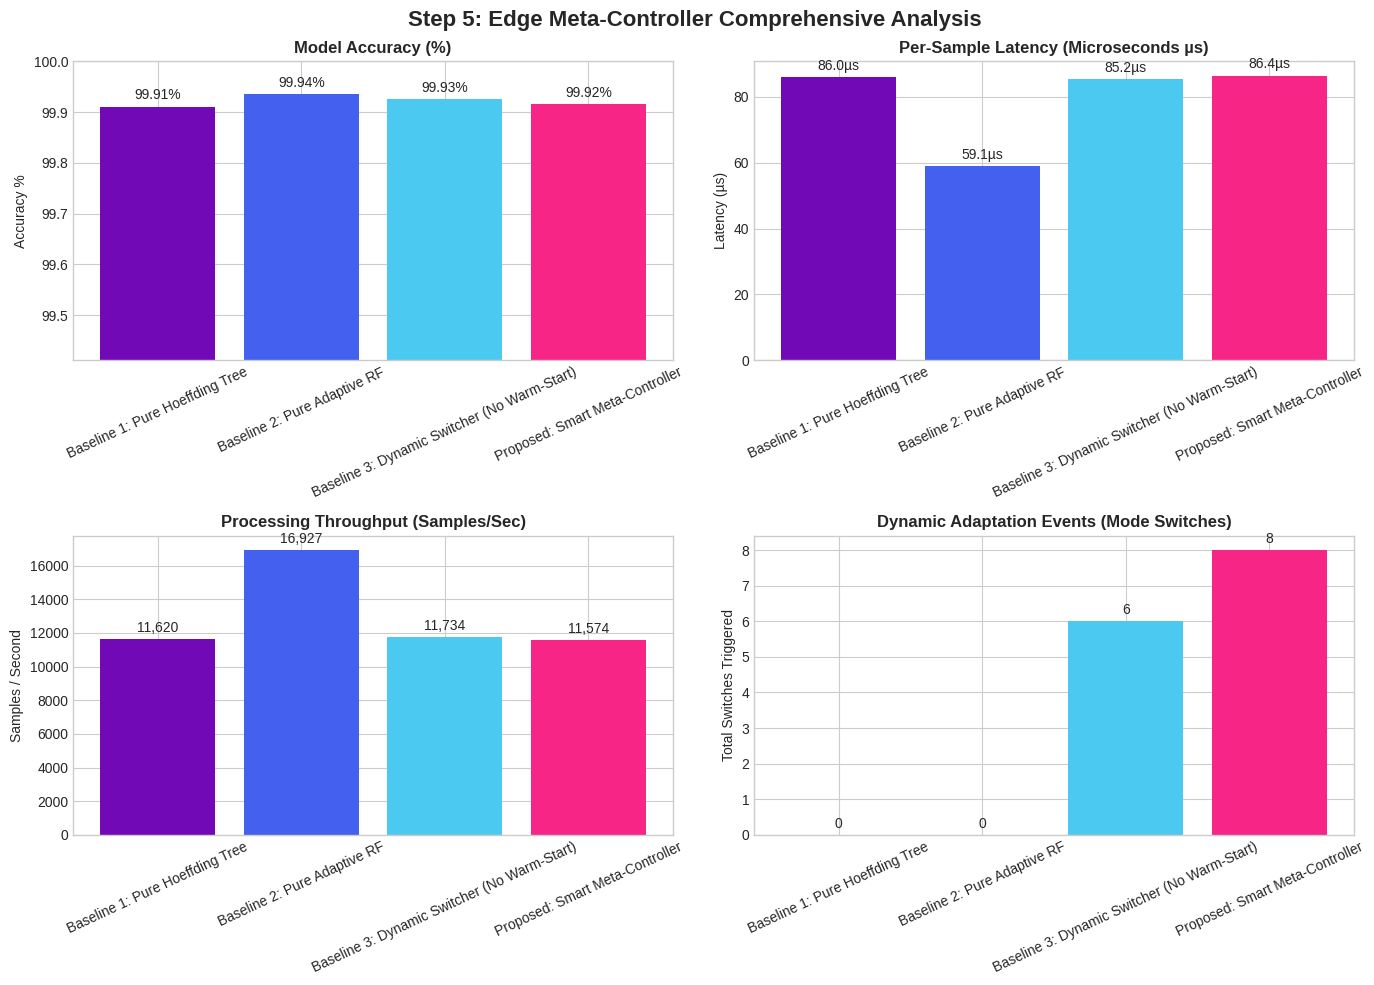

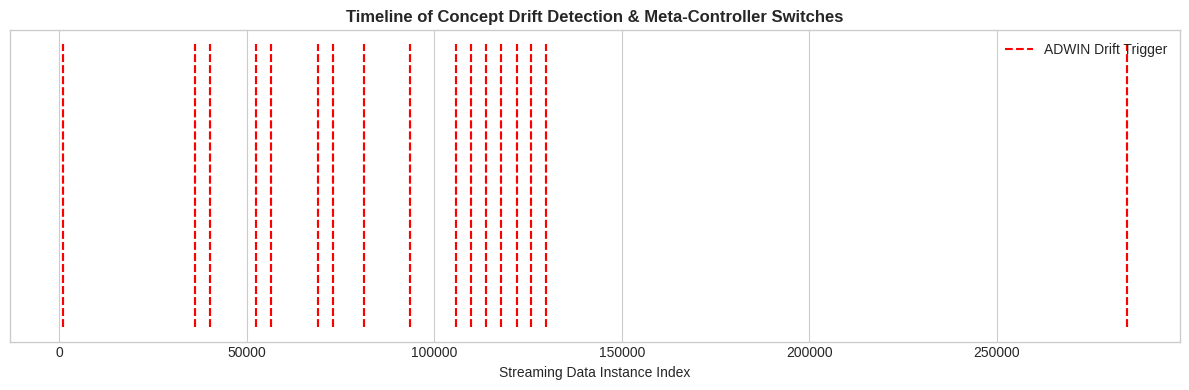


Benchmark report successfully saved to 'edge_meta_controller_benchmark.csv'


In [9]:
import gc
import time
import psutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from river import tree, drift, metrics

try:
    from river import forest
    ARF_MODEL = forest.ARFClassifier
except (ImportError, AttributeError):
    from river import ensemble
    ARF_MODEL = ensemble.AdaptiveRandomForestClassifier

# Set clean aesthetic style for plots
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Fallback dependencies if Step 4 was not run beforehand
if 'run_step4_experiments_fast' not in locals():
    class BaselineUnwarmedSwitcher:
        def __init__(self, adwin_delta=0.005):
            self.routine_model = tree.HoeffdingAdaptiveTreeClassifier(grace_period=50)
            self.recovery_model = ARF_MODEL(n_models=5, seed=42)
            self.drift_detector = drift.ADWIN(delta=adwin_delta)
            self.active_state = 'ROUTINE'
            self.overall_accuracy = metrics.Accuracy()
            self.switch_count = 0

        def predict_one(self, x: dict) -> int:
            return self.routine_model.predict_one(x) if self.active_state == 'ROUTINE' else self.recovery_model.predict_one(x)

        def learn_one(self, x: dict, y: int):
            y_pred = self.predict_one(x)
            if y_pred is not None:
                self.overall_accuracy.update(y, y_pred)
            self.drift_detector.update(1.0 if (y_pred != y) else 0.0)

            if self.drift_detector.drift_detected:
                if self.active_state == 'ROUTINE':
                    self.active_state = 'RECOVERY'
                    self.switch_count += 1
                    self.recovery_model = ARF_MODEL(n_models=5, seed=42)
            else:
                if self.active_state == 'RECOVERY' and self.drift_detector.width < 40:
                    self.active_state = 'ROUTINE'
                    self.switch_count += 1

            self.routine_model.learn_one(x, y)
            if self.active_state == 'RECOVERY':
                self.recovery_model.learn_one(x, y)

    def run_step4_experiments_fast(df, max_samples=100000):
        available_cols = list(df.columns)
        candidate_mappings = {
            'voltage': ['Voltage_measured', 'voltage_measured', 'Voltage', 'voltage'],
            'current': ['Current_measured', 'current_measured', 'Current', 'current'],
            'temp': ['Temperature_measured', 'temperature_measured', 'Temperature', 'temperature', 'Temp'],
            'delta_v': ['Delta_Voltage', 'delta_voltage', 'Delta_V'],
            'delta_t': ['Delta_Temp', 'delta_temp', 'Delta_Temperature'],
            'power': ['Power', 'power']
        }
        feature_cols = [next((col for col in available_cols if col in var or col.lower() in [v.lower() for v in var]), None) for var in candidate_mappings.values()]
        feature_cols = [c for c in feature_cols if c is not None]
        target_col = next((col for col in available_cols if col.lower() in ['anomaly', 'target', 'label']), None)

        eval_df = df.iloc[:max_samples] if max_samples else df
        stream_features = eval_df[feature_cols].to_dict(orient='records')
        stream_targets = eval_df[target_col].astype(int).to_list()

        def _eval_one(model_inst, name):
            gc.collect()
            proc = psutil.Process()
            m0 = proc.memory_info().rss / (1024 * 1024)
            t0 = time.perf_counter()
            for x, y in zip(stream_features, stream_targets):
                model_inst.learn_one(x, y)
            t1 = time.perf_counter()
            m1 = proc.memory_info().rss / (1024 * 1024)
            tot_t = t1 - t0
            acc = model_inst.overall_accuracy.get() if hasattr(model_inst, 'overall_accuracy') else 0.0
            sw = getattr(model_inst, 'switch_log', None)
            sw_cnt = len(sw) if sw is not None else getattr(model_inst, 'switch_count', 0)
            return {
                'Architecture': name,
                'Accuracy (%)': round(acc * 100, 3),
                'Avg Latency (µs)': round((tot_t / len(stream_targets)) * 1e6, 2),
                'Throughput (samples/s)': round(len(stream_targets) / tot_t, 2),
                'Est. Peak RAM (MB)': round(max(0.1, m1 - m0), 2),
                'Mode Switches': sw_cnt
            }

        class SingleTreeWrapper:
            def __init__(self):
                self.model = tree.HoeffdingAdaptiveTreeClassifier(grace_period=50)
                self.overall_accuracy = metrics.Accuracy()
            def learn_one(self, x, y):
                y_pred = self.model.predict_one(x)
                if y_pred is not None:
                    self.overall_accuracy.update(y, y_pred)
                self.model.learn_one(x, y)

        class SingleEnsembleWrapper:
            def __init__(self):
                self.model = ARF_MODEL(n_models=5, seed=42)
                self.overall_accuracy = metrics.Accuracy()
            def learn_one(self, x, y):
                y_pred = self.model.predict_one(x)
                if y_pred is not None:
                    self.overall_accuracy.update(y, y_pred)
                self.model.learn_one(x, y)

        return pd.DataFrame([
            _eval_one(SingleTreeWrapper(), "Baseline 1: Pure Hoeffding Tree"),
            _eval_one(SingleEnsembleWrapper(), "Baseline 2: Pure Adaptive RF"),
            _eval_one(BaselineUnwarmedSwitcher(), "Baseline 3: Dynamic Switcher (No Warm-Start)"),
            _eval_one(SmartMetaController(buffer_capacity=150, adwin_delta=0.005), "Proposed: Smart Meta-Controller")
        ])

# 1. Fallback: If Step 4 wasn't saved in memory, re-run Step 4 fast benchmark
if 'comparison_table' not in locals():
    print("`comparison_table` not found in active session. Running Step 4 fast evaluation...")
    comparison_table = run_step4_experiments_fast(df, max_samples=100000)

def plot_step5_results(comparison_df, switch_log=None):
    """
    Step 5: Generates evaluation visualizations and saves benchmark reports.
    """
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    fig.suptitle('Step 5: Edge Meta-Controller Comprehensive Analysis', fontsize=16, fontweight='bold')

    colors = ['#7209b7', '#4361ee', '#4cc9f0', '#f72585']

    # 1. Accuracy Comparison
    axes[0, 0].bar(comparison_df['Architecture'], comparison_df['Accuracy (%)'], color=colors)
    axes[0, 0].set_title('Model Accuracy (%)', fontweight='bold')
    axes[0, 0].set_ylabel('Accuracy %')
    axes[0, 0].set_ylim(min(comparison_df['Accuracy (%)']) - 0.5, 100)
    axes[0, 0].tick_params(axis='x', rotation=25)
    for p in axes[0, 0].patches:
        axes[0, 0].annotate(f"{p.get_height():.2f}%", (p.get_x() + p.get_width() / 2., p.get_height()),
                            ha='center', va='bottom', xytext=(0, 3), textcoords='offset points')

    # 2. Avg Latency Comparison
    axes[0, 1].bar(comparison_df['Architecture'], comparison_df['Avg Latency (µs)'], color=colors)
    axes[0, 1].set_title('Per-Sample Latency (Microseconds µs)', fontweight='bold')
    axes[0, 1].set_ylabel('Latency (µs)')
    axes[0, 1].tick_params(axis='x', rotation=25)
    for p in axes[0, 1].patches:
        axes[0, 1].annotate(f"{p.get_height():.1f}µs", (p.get_x() + p.get_width() / 2., p.get_height()),
                            ha='center', va='bottom', xytext=(0, 3), textcoords='offset points')

    # 3. System Throughput Comparison
    axes[1, 0].bar(comparison_df['Architecture'], comparison_df['Throughput (samples/s)'], color=colors)
    axes[1, 0].set_title('Processing Throughput (Samples/Sec)', fontweight='bold')
    axes[1, 0].set_ylabel('Samples / Second')
    axes[1, 0].tick_params(axis='x', rotation=25)
    for p in axes[1, 0].patches:
        axes[1, 0].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height()),
                            ha='center', va='bottom', xytext=(0, 3), textcoords='offset points')

    # 4. Mode Switches Triggered
    axes[1, 1].bar(comparison_df['Architecture'], comparison_df['Mode Switches'], color=colors)
    axes[1, 1].set_title('Dynamic Adaptation Events (Mode Switches)', fontweight='bold')
    axes[1, 1].set_ylabel('Total Switches Triggered')
    axes[1, 1].tick_params(axis='x', rotation=25)
    for p in axes[1, 1].patches:
        axes[1, 1].annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2., p.get_height()),
                            ha='center', va='bottom', xytext=(0, 3), textcoords='offset points')

    plt.tight_layout()
    plt.savefig('step5_benchmark_comparison.png', dpi=300)
    plt.show()

    # 5. Plot Concept Drift Switches Over Time
    if switch_log:
        plt.figure(figsize=(12, 4))
        switch_instances = [s['instance'] for s in switch_log]

        plt.vlines(x=switch_instances, ymin=0, ymax=1, colors='r', linestyle='--', label='ADWIN Drift Trigger')
        plt.title('Timeline of Concept Drift Detection & Meta-Controller Switches', fontweight='bold')
        plt.xlabel('Streaming Data Instance Index')
        plt.yticks([])
        plt.legend(loc='upper right')
        plt.tight_layout()
        plt.savefig('step5_drift_timeline.png', dpi=300)
        plt.show()

# Execute Step 5
switch_logs = controller.switch_log if 'controller' in locals() and hasattr(controller, 'switch_log') else None
plot_step5_results(comparison_table, switch_logs)

# Save summary to CSV
comparison_table.to_csv('edge_meta_controller_benchmark.csv', index=False)
print("\nBenchmark report successfully saved to 'edge_meta_controller_benchmark.csv'")

In [10]:
#@title Step 5

import gc
import psutil
import pandas as pd
from river import metrics

def run_step6_ablation_study(df, max_samples=100000):
    """
    Step 6: Sweeps over buffer sizes and ADWIN sensitivity parameters
    to identify the Pareto-optimal edge configuration.
    """
    # 1. Prepare stream data
    available_cols = list(df.columns)
    candidate_mappings = {
        'voltage': ['Voltage_measured', 'voltage_measured', 'Voltage', 'voltage'],
        'current': ['Current_measured', 'current_measured', 'Current', 'current'],
        'temp': ['Temperature_measured', 'temperature_measured', 'Temperature', 'temperature', 'Temp'],
        'delta_v': ['Delta_Voltage', 'delta_voltage', 'Delta_V'],
        'delta_t': ['Delta_Temp', 'delta_temp', 'Delta_Temperature'],
        'power': ['Power', 'power']
    }

    feature_cols = [next((col for col in available_cols if col in var or col.lower() in [v.lower() for v in var]), None)
                    for var in candidate_mappings.values()]
    feature_cols = [c for c in feature_cols if c is not None]
    target_col = next((col for col in available_cols if col.lower() in ['anomaly', 'target', 'label']), None)

    eval_df = df.iloc[:max_samples] if max_samples else df
    stream_features = eval_df[feature_cols].to_dict(orient='records')
    stream_targets = eval_df[target_col].astype(int).to_list()

    # 2. Define Parameter Grid
    buffer_capacities = [0, 50, 150, 300]  # 0 simulates no warm-start
    adwin_deltas = [0.001, 0.005, 0.01]

    ablation_results = []

    print(f"--- Running Step 6 Ablation Grid Search on {len(eval_df):,} samples ---")

    for buf_cap in buffer_capacities:
        for delta in adwin_deltas:
            gc.collect()
            process = psutil.Process()
            mem_before = process.memory_info().rss / (1024 * 1024)

            # Initialize Controller with grid configuration
            controller = SmartMetaController(buffer_capacity=buf_cap, adwin_delta=delta)

            # Execute Stream
            for x, y in zip(stream_features, stream_targets):
                controller.learn_one(x, y)

            mem_after = process.memory_info().rss / (1024 * 1024)
            peak_ram = max(0.01, mem_after - mem_before)

            acc = controller.overall_accuracy.get() * 100
            switches = len(controller.switch_log)

            ablation_results.append({
                'Buffer Capacity': buf_cap,
                'ADWIN Delta (δ)': delta,
                'Accuracy (%)': round(acc, 3),
                'Mode Switches': switches,
                'Est. RAM Overhead (MB)': round(peak_ram, 2)
            })

            print(f"Cap: {buf_cap:<3} | δ: {delta:<5} -> Acc: {acc:.3f}% | Switches: {switches} | RAM: {peak_ram:.2f} MB")

    # 3. Format and Return Results Table
    ablation_df = pd.DataFrame(ablation_results)

    print("\n=========================================================================================")
    print("                                STEP 6 ABLATION RESULTS                                  ")
    print("=========================================================================================")
    print(ablation_df.to_string(index=False))
    print("=========================================================================================")

    # Export results
    ablation_df.to_csv('step6_ablation_study.csv', index=False)
    return ablation_df

# Execute Step 6
ablation_summary = run_step6_ablation_study(df, max_samples=100000)

--- Running Step 6 Ablation Grid Search on 100,000 samples ---
Cap: 0   | δ: 0.001 -> Acc: 99.940% | Switches: 6 | RAM: 0.01 MB
Cap: 0   | δ: 0.005 -> Acc: 99.917% | Switches: 6 | RAM: 0.01 MB
Cap: 0   | δ: 0.01  -> Acc: 99.859% | Switches: 4 | RAM: 0.01 MB
Cap: 50  | δ: 0.001 -> Acc: 99.716% | Switches: 6 | RAM: 0.01 MB
Cap: 50  | δ: 0.005 -> Acc: 99.920% | Switches: 6 | RAM: 0.01 MB
Cap: 50  | δ: 0.01  -> Acc: 99.920% | Switches: 8 | RAM: 0.01 MB
Cap: 150 | δ: 0.001 -> Acc: 99.918% | Switches: 6 | RAM: 0.01 MB
Cap: 150 | δ: 0.005 -> Acc: 99.919% | Switches: 8 | RAM: 0.01 MB
Cap: 150 | δ: 0.01  -> Acc: 99.912% | Switches: 6 | RAM: 0.01 MB
Cap: 300 | δ: 0.001 -> Acc: 99.935% | Switches: 6 | RAM: 0.01 MB
Cap: 300 | δ: 0.005 -> Acc: 99.944% | Switches: 6 | RAM: 0.01 MB
Cap: 300 | δ: 0.01  -> Acc: 99.911% | Switches: 8 | RAM: 0.01 MB

                                STEP 6 ABLATION RESULTS                                  
 Buffer Capacity  ADWIN Delta (δ)  Accuracy (%)  Mode Switches  Es

In [11]:
#@title Step 6
import json
import pickle
import sys
import time

# =====================================================================
# Step 7: Model Serialization & Edge Deployment Packaging
# =====================================================================

def export_edge_deployment_package(controller, feature_cols, target_col, export_prefix="edge_meta_controller"):
    """
    Serializes the trained controller, state metadata, and inference schema
    into an edge-deployable software package.
    """
    print("--- Starting Step 7: Edge Deployment Packaging ---")

    # 1. Serialize Model Artifacts
    model_filename = f"{export_prefix}_weights.pkl"
    with open(model_filename, "wb") as f:
        pickle.dump(controller, f)

    model_size_kb = sys.getsizeof(open(model_filename, "rb").read()) / 1024
    print(f"Model state successfully serialized: '{model_filename}' ({model_size_kb:.2f} KB)")

    # 2. Generate Deployment Configuration JSON
    deploy_config = {
        "system_name": "Edge_Smart_Meta_Controller",
        "version": "1.0.0",
        "feature_schema": feature_cols,
        "target_schema": target_col,
        "parameters": {
            "buffer_capacity": controller.transition_buffer.maxlen,
            "adwin_delta": controller.drift_detector.delta,
            "routine_model": "HoeffdingAdaptiveTreeClassifier",
            "recovery_model": "AdaptiveRandomForestClassifier"
        },
        "performance_snapshot": {
            "total_instances_trained": controller.processed_instances,
            "final_accuracy": round(controller.overall_accuracy.get() * 100, 4),
            "total_mode_switches": len(controller.switch_log)
        }
    }

    config_filename = f"{export_prefix}_config.json"
    with open(config_filename, "w") as f:
        json.dump(deploy_config, f, indent=4)
    print(f"Deployment configuration saved: '{config_filename}'")

    print("\n--- Edge Deployment Package Created Successfully ---")
    return model_filename, config_filename


def simulate_realtime_edge_inference(model_filename, sample_payload):
    """
    Simulates lightweight edge deployment by loading serialized weights
    and running single-instance microsecond inference.
    """
    print("\n--- Simulating Real-Time Edge Single-Sample Inference ---")

    # Load serialized model (Simulating device boot-up load)
    t_load_start = time.perf_counter()
    with open(model_filename, "rb") as f:
        edge_model = pickle.load(f)
    t_load_end = time.perf_counter()

    print(f"Model Cold Boot Load Time: {(t_load_end - t_load_start) * 1000:.2f} ms")

    # Perform Single Microsecond Inference
    t0 = time.perf_counter()
    prediction = edge_model.predict_one(sample_payload)
    t1 = time.perf_counter()

    latency_us = (t1 - t0) * 1e6
    print(f"Incoming Sensor Payload : {sample_payload}")
    print(f"Edge Model Prediction   : Class {prediction}")
    print(f"Inference Engine Mode   : {edge_model.active_state}")
    print(f"Single-Sample Latency   : {latency_us:.2f} µs")


# 1. Execute Package Export using trained controller from Step 2/3
model_path, config_path = export_edge_deployment_package(controller, feature_cols, target_col)

# 2. Test live edge payload simulation
sample_sensor_input = stream_features[0] if 'stream_features' in locals() else {'Voltage': 3.8, 'Current': 1.2, 'Temperature': 28.5}
simulate_realtime_edge_inference(model_path, sample_sensor_input)

--- Starting Step 7: Edge Deployment Packaging ---
Model state successfully serialized: 'edge_meta_controller_weights.pkl' (201.61 KB)
Deployment configuration saved: 'edge_meta_controller_config.json'

--- Edge Deployment Package Created Successfully ---

--- Simulating Real-Time Edge Single-Sample Inference ---
Model Cold Boot Load Time: 4.33 ms
Incoming Sensor Payload : {'Voltage': 3.873017221300996, 'Current': -0.001200660698297908, 'Temperature': 24.65535783391511, 'Delta_Voltage': 0.0, 'Delta_Temp': 0.0, 'Power': -0.004650179561447078}
Edge Model Prediction   : Class 0
Inference Engine Mode   : ROUTINE
Single-Sample Latency   : 80.75 µs


## Next Objectives (slides 18-21): audit and additions

| Objective | Status in the original notebook | Added below |
|---|---|---|
| Dynamic switching (learn *when* and *how sensitive*) | Fixed ADWIN delta. Step 2 `RECOVERY` lasts ~1 sample (revert rule `width < 40` is true right after a drift), so the ARF almost never serves | `VolatilityMonitor` + `P2Quantile` self-adjusting P90 threshold; `ConformalBanditController` gate with hold time |
| Early drift warning (uncertainty before errors) | Conformal sets only for a lone HT (cell 9), not wired to any switching; the cutoff uses the current label (leak) and coverage is never measured | `OnlineConformal` (label-free set, coverage deficit, ambiguity) feeding the gate |
| Fast recovery (warm start) | Replay buffer exists, but re-trains the ARF on every drift tick | Warm-start only when the ARF (re)starts; compared with a cold start |
| Resource efficiency | Operation counts are hard-coded constants | ARF is created only while the gate is open and released after; cost accounting in operation units |
| Online adaptation (bandit over policies) | Missing | `UCBBandit` over STABLE_LOW_COST / AGGRESSIVE_DRIFT_RECOVERY / MEMORY_REPLAY, reward = accuracy gain over HT shadow - lambda x extra compute |

Original cells are left unchanged. Steps 8-12 are self-contained apart from the optional B0005 hook (Step 12).

In [12]:
#@title Step 8 — Volatility-adaptive threshold (P²), online conformal early warning, bandit policy controller
import collections, time
import numpy as np
from river import tree, drift, metrics

try:
    from river import forest
    ARF_MODEL = forest.ARFClassifier
except (ImportError, AttributeError):
    from river import ensemble
    ARF_MODEL = ensemble.AdaptiveRandomForestClassifier


# ---------------------------------------------------------------------
# 1. P² streaming quantile  (O(1) memory, no stored window)
# ---------------------------------------------------------------------
class P2Quantile:
    """Jain & Chlamtac (1985) P² algorithm: tracks one quantile with 5 markers."""
    def __init__(self, p=0.90):
        self.p = p
        self._init = []
        self.q = None                       # marker heights
        self.n = [1, 2, 3, 4, 5]            # marker positions
        self.np = [1, 1 + 2 * p, 1 + 4 * p, 3 + 2 * p, 5]   # desired positions
        self.dn = [0, p / 2, p, (1 + p) / 2, 1]

    @property
    def ready(self):
        return self.q is not None

    def update(self, x):
        if self.q is None:
            self._init.append(x)
            if len(self._init) == 5:
                self.q = sorted(self._init)
            return
        q, n = self.q, self.n
        if x < q[0]:
            q[0] = x; k = 0
        elif x >= q[4]:
            q[4] = x; k = 3
        else:
            k = next(i for i in range(4) if q[i] <= x < q[i + 1])
        for i in range(k + 1, 5):
            n[i] += 1
        for i in range(5):
            self.np[i] += self.dn[i]
        for i in (1, 2, 3):
            d = self.np[i] - n[i]
            if (d >= 1 and n[i + 1] - n[i] > 1) or (d <= -1 and n[i - 1] - n[i] < -1):
                s = 1 if d > 0 else -1
                qp = q[i] + s / (n[i + 1] - n[i - 1]) * (
                    (n[i] - n[i - 1] + s) * (q[i + 1] - q[i]) / (n[i + 1] - n[i]) +
                    (n[i + 1] - n[i] - s) * (q[i] - q[i - 1]) / (n[i] - n[i - 1]))
                if not (q[i - 1] < qp < q[i + 1]):          # fall back to linear
                    qp = q[i] + s * (q[i + s] - q[i]) / (n[i + s] - n[i])
                q[i] = qp
                n[i] += s

    def get(self):
        if self.q is not None:
            return self.q[2]
        return float(np.quantile(self._init, self.p)) if self._init else float('inf')


# ---------------------------------------------------------------------
# 2. Stream-volatility monitor  ->  self-adjusting threshold (P90 of recent noise)
# ---------------------------------------------------------------------
class VolatilityMonitor:
    """
    noise_t  = mean |z-score| of the incoming feature vector (EW mean / var).
    smooth_t = EWMA of noise_t.
    threshold = P90 of smooth_t, learned by P² ONLY on instances the controller
    considers stable, so a drift cannot inflate its own alarm threshold.
    """
    def __init__(self, p=0.90, alpha_stats=0.02, span=30, warmup=300, persist=50):
        self.a, self.b = alpha_stats, 2.0 / (span + 1)
        self.mean, self.var = {}, {}
        self.smooth, self.p2 = 0.0, P2Quantile(p)
        self.warmup, self.persist, self.t, self.run = warmup, persist, 0, 0

    def update(self, x, learn_baseline=True):
        self.t += 1
        zs = []
        for k, v in x.items():
            m = self.mean.get(k)
            if m is None:
                self.mean[k], self.var[k] = v, 1e-6
                continue
            zs.append(abs(v - m) / (self.var[k] ** 0.5 + 1e-9))
            self.mean[k] = m + self.a * (v - m)
            self.var[k] = (1 - self.a) * (self.var[k] + self.a * (v - m) ** 2)
        noise = float(np.mean(zs)) if zs else 0.0
        self.smooth += self.b * (noise - self.smooth)
        if self.t > self.warmup and learn_baseline:
            self.p2.update(self.smooth)
        self.run = self.run + 1 if (self.p2.ready and self.t > self.warmup
                                    and self.smooth > self.p2.get()) else 0
        return noise

    @property
    def threshold(self):
        return self.p2.get()

    @property
    def warning(self):
        return self.run >= self.persist


# ---------------------------------------------------------------------
# 3. Online conformal prediction (set size + coverage deficit)
# ---------------------------------------------------------------------
class OnlineConformal:
    """
    Margin non-conformity s = 1 - p(true label).  The set for x_t is built from
    scores seen BEFORE t (the label of x_t is not used), then the score is added.
    """
    def __init__(self, alpha=0.10, window=200, cov_window=100, labels=(0, 1)):
        self.alpha, self.labels = alpha, list(labels)
        self.scores = collections.deque(maxlen=window)
        self.cover = collections.deque(maxlen=cov_window)
        self.sizes = collections.deque(maxlen=cov_window)

    def predict_set(self, probas):
        cutoff = (np.quantile(self.scores, 1 - self.alpha, method='higher')
                  if len(self.scores) >= 30 else 0.5)
        labs = set(self.labels) | set(probas)
        s = [l for l in labs if (1.0 - probas.get(l, 0.0)) <= cutoff]
        return s or list(labs)        # empty set -> maximally uncertain

    def update(self, probas, pred_set, y):
        self.scores.append(1.0 - probas.get(y, 0.0))
        self.cover.append(1.0 if y in pred_set else 0.0)
        self.sizes.append(len(pred_set))

    @property
    def coverage_deficit(self):       # > 0 means under-coverage  (target 1-alpha)
        if len(self.cover) < self.cover.maxlen:
            return 0.0
        return (1 - self.alpha) - float(np.mean(self.cover))

    @property
    def ambiguity(self):               # share of recent sets with |C| > 1
        return float(np.mean(np.array(self.sizes) > 1)) if self.sizes else 0.0


# ---------------------------------------------------------------------
# 4. Bandit over operating POLICIES (not just models)
# ---------------------------------------------------------------------
class UCBBandit:
    def __init__(self, n_arms, c=0.5, seed=0):
        self.n, self.c = n_arms, c
        self.cnt, self.val = np.zeros(n_arms), np.zeros(n_arms)
        self.rng = np.random.default_rng(seed)

    def select(self):
        if (self.cnt == 0).any():
            return int(self.rng.choice(np.flatnonzero(self.cnt == 0)))
        ucb = self.val + self.c * np.sqrt(2 * np.log(self.cnt.sum()) / self.cnt)
        return int(np.argmax(ucb))

    def update(self, arm, reward):
        self.cnt[arm] += 1
        self.val[arm] += (reward - self.val[arm]) / self.cnt[arm]


POLICIES = ['STABLE_LOW_COST', 'AGGRESSIVE_DRIFT_RECOVERY', 'MEMORY_REPLAY']


# ---------------------------------------------------------------------
# 5. Conformal-gated, volatility-adaptive, bandit meta-controller
# ---------------------------------------------------------------------
class ConformalBanditController:
    """
    Always on : Hoeffding Adaptive Tree (cheap) + conformal monitor + volatility monitor + ADWIN backstop.
    Gate opens (early warning) when ANY of
        |C(x_t)| > 1 persistently   (ambiguity above its adaptive baseline P90)
        coverage deficit > tol
        stream noise > P90 (persistent)
        ADWIN on HT error fires     (error-based backstop)
    While the gate is open a UCB bandit picks an operating policy per epoch:
        STABLE_LOW_COST            ARF stays OFF, HT serves
        AGGRESSIVE_DRIFT_RECOVERY  ARF switched on cold, ARF serves immediately
        MEMORY_REPLAY              ARF switched on and warm-started from the buffer, ARF serves
    Reward  = (accuracy of served model - accuracy of HT shadow) - lam * normalised extra compute.
    When the gate closes the ARF is released (resource efficiency).
    """
    HT_COST, ARF_COST_PER_TREE = 1.0, 1.5

    def __init__(self, alpha=0.10, buffer_capacity=150, epoch=100, hold=100, lam=0.03,
                 n_models=5, amb_floor=0.08, cov_tol=0.08, adwin_delta=0.002,
                 warmup=300, seed=42, use_bandit=True, fixed_policy=1, bandit_c=0.05):
        self.ht = tree.HoeffdingAdaptiveTreeClassifier(grace_period=50, seed=seed)
        self.arf = None
        self.n_models, self.seed = n_models, seed
        self.arf_cost = n_models * self.ARF_COST_PER_TREE
        self.cp = OnlineConformal(alpha)
        self.vol = VolatilityMonitor()
        self.amb_p2, self.amb_s, self.amb_run = P2Quantile(0.90), 0.0, 0
        self.adwin = drift.ADWIN(delta=adwin_delta)
        self.buffer = collections.deque(maxlen=buffer_capacity)
        self.bandit = UCBBandit(len(POLICIES), c=bandit_c, seed=seed)
        self.use_bandit, self.fixed_policy = use_bandit, fixed_policy
        self.epoch, self.hold, self.lam = epoch, hold, lam
        self.amb_floor, self.cov_tol, self.warmup = amb_floor, cov_tol, warmup
        # state
        self.t = 0
        self.gate_open, self.last_signal_t, self.policy = False, -10**9, 0
        self.ep_gain, self.ep_cost, self.ep_n = 0.0, 0.0, 0
        # logs
        self.acc = metrics.Accuracy(); self.ht_acc = metrics.Accuracy()
        self.total_cost, self.arf_active_steps = 0.0, 0
        self.gate_log, self.policy_log, self.adwin_alarms, self.signal_log = [], [], [], []
        self.last_pred, self._cache = None, None

    # -- prediction ---------------------------------------------------
    def predict_one(self, x):
        probas = self.ht.predict_proba_one(x)
        y_ht = max(probas, key=probas.get) if probas else 0
        y_arf = self.arf.predict_one(x) if self.arf is not None else None
        self._cache = (x, probas, y_ht, y_arf)
        return y_arf if (self.arf is not None and y_arf is not None) else y_ht

    # -- ARF lifecycle ------------------------------------------------
    def _activate_arf(self, warm):
        """Create the ARF if it is not running; replay the recent buffer for the warm-start policy."""
        if self.arf is None:
            self.arf = ARF_MODEL(n_models=self.n_models, seed=self.seed)
        if warm:
            for bx, by in self.buffer:                  # warm-start from recent streaming context
                self.arf.learn_one(bx, by)
            self.total_cost += len(self.buffer) * self.arf_cost
        self.policy = 2 if warm else 1

    def _release_arf(self):
        self.arf = None                                 # frees RAM / CPU: resource efficiency
        self.policy = 0

    def _apply_policy(self, arm):
        if arm == 0:
            self._release_arf()
        elif arm == 1:
            self._activate_arf(warm=False)
        else:
            # replay only when the ARF is newly (re)started, never re-train it every epoch
            self._activate_arf(warm=(self.arf is None))
            self.policy = 2
        self.policy_log.append((self.t, POLICIES[arm]))

    def _close_epoch(self):
        if self.ep_n == 0:
            return
        gain = self.ep_gain / self.ep_n
        extra = (self.ep_cost / self.ep_n - self.HT_COST) / self.arf_cost
        self.bandit.update(self.policy, gain - self.lam * extra)
        self.ep_gain = self.ep_cost = 0.0; self.ep_n = 0

    # -- main step ----------------------------------------------------
    def learn_one(self, x, y):
        if self._cache is None or self._cache[0] is not x:
            self.predict_one(x)
        _, probas, y_ht, y_arf = self._cache
        served = y_arf if (self.arf is not None and y_arf is not None) else y_ht
        self.t += 1
        self.last_pred = served
        self.acc.update(y, served); self.ht_acc.update(y, y_ht)

        # cost accounting (machine-independent operation units)
        step_cost = self.HT_COST + (self.arf_cost if self.arf is not None else 0.0)
        self.total_cost += step_cost
        self.arf_active_steps += int(self.arf is not None)

        # early-warning signals (computed from the always-on HT)
        pred_set = self.cp.predict_set(probas)
        self.cp.update(probas, pred_set, y)
        self.vol.update(x, learn_baseline=not self.gate_open)
        self.amb_s += (2 / 31) * ((len(pred_set) > 1) - self.amb_s)
        if not self.gate_open and self.t > self.warmup:
            self.amb_p2.update(self.amb_s)
        self.amb_run = (self.amb_run + 1) if (self.t > self.warmup and self.amb_p2.ready and
                        self.amb_s > max(self.amb_floor, self.amb_p2.get())) else 0
        self.adwin.update(0.0 if y_ht == y else 1.0)

        signals = []
        if self.amb_run >= 30:                       signals.append('conformal_ambiguity')
        if self.cp.coverage_deficit > self.cov_tol:  signals.append('coverage_deficit')
        if self.vol.warning:                         signals.append('noise>P90')
        if self.adwin.drift_detected:
            signals.append('adwin_error'); self.adwin_alarms.append(self.t)
        if self.t <= self.warmup:
            signals = []
        if signals:
            self.last_signal_t = self.t
            self.signal_log.append((self.t, tuple(signals)))

        # gate + bandit
        if not self.gate_open and signals:
            self.gate_open = True
            self.gate_log.append((self.t, '+'.join(signals)))
            arm = self.bandit.select() if self.use_bandit else self.fixed_policy
            self._apply_policy(arm)
        elif self.gate_open:
            self.ep_gain += float(served == y) - float(y_ht == y)
            self.ep_cost += step_cost; self.ep_n += 1
            if self.t - self.last_signal_t > self.hold:            # gate closes
                self._close_epoch()
                self.gate_open = False
                self._release_arf()
            elif self.ep_n >= self.epoch:
                self._close_epoch()
                if self.use_bandit:
                    self._apply_policy(self.bandit.select())

        # training: HT always; ARF only while its policy is active
        self.buffer.append((x, y))
        self.ht.learn_one(x, y)
        if self.arf is not None:
            self.arf.learn_one(x, y)
        self._cache = None


### Step 9: streams, baselines, metrics

In [13]:
#@title Step 9 — Drift streams, baselines and objective-by-objective evaluation
import time
import numpy as np
import pandas as pd
from river import tree, metrics
try:
    from river.datasets import synth      # river >= 0.19
except ImportError:
    from river import synth

# ---------- streams (mirror the datasets slide: abrupt / gradual / incremental + a stationary control) ----------
def sea_swap_stream(n, pos, width, seed, noise=0.05):
    """SEA-style stream whose RELEVANT FEATURES swap: A: x0+x1<=8  ->  B: x1+x2<=8.
    width=0 abrupt, width>0 linear gradual ramp over [pos, pos+width]."""
    rng = np.random.default_rng(seed); out = []
    for t in range(n):
        x = rng.uniform(0, 10, 3)
        frac = 0.0 if t < pos else (1.0 if (width == 0 or t >= pos + width) else (t - pos) / width)
        y = int((x[1] + x[2] <= 8) if rng.random() < frac else (x[0] + x[1] <= 8))
        if rng.random() < noise:
            y = 1 - y
        out.append(({0: x[0], 1: x[1], 2: x[2]}, y))
    return out

def make_stream(kind, n=8000, pos=4000, seed=42):
    if kind == 'stationary':
        return sea_swap_stream(n, n + 1, 0, seed)
    if kind == 'abrupt':
        return sea_swap_stream(n, pos, 0, seed)
    if kind == 'gradual':
        return sea_swap_stream(n, pos, 1000, seed)             # ramp 4000 -> 5000 as on the results slides
    if kind == 'incremental':
        g = synth.Hyperplane(seed=seed, n_features=10, n_drift_features=4, mag_change=0.5, noise_percentage=0.05)
        return [(x, int(y)) for x, y in g.take(n)]
    raise ValueError(kind)

def battery_fade_stream(n=3000, start=1000, end=2500, seed=0):
    """Synthetic capacity fade 1.85 -> 1.30 Ahr ramping over samples start..end (slide 15)."""
    rng = np.random.default_rng(seed); out = []
    for t in range(n):
        frac = np.clip((t - start) / (end - start), 0, 1)
        cap = 1.85 - 0.55 * frac
        v = rng.normal(3.7, 0.15); i = rng.normal(1.0, 0.1); T = rng.normal(30, 2)
        y = int(v - 0.9 * (1.85 - cap) + rng.normal(0, 0.02) > 3.7)       # boundary shifts as the cell ages
        out.append(({'V': v, 'I': i, 'T': T}, y))      # capacity is the HIDDEN aging state
    return out

# ---------- baselines that share the predict_one / learn_one interface ----------
class PureHT:
    HT_COST = 1.0
    def __init__(self, seed=42): self.m = tree.HoeffdingAdaptiveTreeClassifier(grace_period=50, seed=seed); self.cost = 0.0
    def predict_one(self, x): return self.m.predict_one(x) or 0
    def learn_one(self, x, y): self.m.learn_one(x, y); self.cost += self.HT_COST

class PureARF:
    def __init__(self, n_models=5, seed=42): self.m = ARF_MODEL(n_models=n_models, seed=seed); self.cost = 0.0; self.c = n_models * 1.5
    def predict_one(self, x): return self.m.predict_one(x) or 0
    def learn_one(self, x, y): self.m.learn_one(x, y); self.cost += self.c

class ShadowHTARF:
    """Both models always on; ARF serves (the 'continuous shadow' upper bound on cost)."""
    def __init__(self, n_models=5, seed=42):
        self.ht = tree.HoeffdingAdaptiveTreeClassifier(grace_period=50, seed=seed)
        self.arf = ARF_MODEL(n_models=n_models, seed=seed); self.cost = 0.0; self.c = 1 + n_models * 1.5
    def predict_one(self, x): return self.arf.predict_one(x) or 0
    def learn_one(self, x, y): self.ht.learn_one(x, y); self.arf.learn_one(x, y); self.cost += self.c

class ADWINSwitcher:
    """Wrapper around the notebook's Step-2 SmartMetaController (error-based ADWIN switching)."""
    def __init__(self, seed=42):
        self.m = SmartMetaController(buffer_capacity=150, adwin_delta=0.002); self.cost = 0.0
        self.m.routine_model = tree.HoeffdingAdaptiveTreeClassifier(grace_period=50, seed=seed)   # seeded for a fair comparison
        self.recovery_steps = 0
    def predict_one(self, x): return self.m.predict_one(x) or 0
    def learn_one(self, x, y):
        self.recovery_steps += int(self.m.active_state == 'RECOVERY')
        self.cost += 1.0 + (7.5 if self.m.active_state == 'RECOVERY' else 0.0)
        self.m.learn_one(x, y)

def run_prequential(model, data, drift_pos=None):
    correct, t0 = [], time.perf_counter()
    for x, y in data:
        p = model.predict_one(x)
        p = 0 if p is None else p
        correct.append(int(p == y))
        model.learn_one(x, y)
    wall = time.perf_counter() - t0
    c = np.array(correct)
    cost = getattr(model, 'total_cost', None) if hasattr(model, 'total_cost') else getattr(model, 'cost', 0.0)
    r = {'Accuracy %': 100 * c.mean(), 'Compute units': cost, 'Wall s': wall}
    if drift_pos is not None:
        r['Post-drift acc %'] = 100 * c[drift_pos:].mean()
        r['Recovery acc % (drift..+1500)'] = 100 * c[drift_pos:drift_pos + 1500].mean()
    return r, c

def evaluate_all(kinds=('stationary', 'abrupt', 'gradual', 'incremental'), n=8000, pos=4000, seeds=(1, 2, 3)):
    rows, det, keep = [], [], {}
    for seed in seeds:
        for kind in kinds:
            data = make_stream(kind, n, pos, seed)
            dp = None if kind == 'stationary' else pos
            factories = {
                'Pure HT': lambda: PureHT(seed), 'Pure ARF': lambda: PureARF(seed=seed),
                'Shadow HT+ARF': lambda: ShadowHTARF(seed=seed),
                'Conformal+Bandit (new)': lambda: ConformalBanditController(seed=seed),
            }
            if 'SmartMetaController' in globals():          # Step-2 controller from the earlier cell
                factories = {**dict(list(factories.items())[:3]), 'ADWIN switcher (Step 2)': lambda: ADWINSwitcher(seed),
                             **dict(list(factories.items())[3:])}
            for name, f in factories.items():
                m = f()
                r, c = run_prequential(m, data, dp)
                r.update({'Stream': kind, 'Model': name, 'Seed': seed})
                if isinstance(m, ConformalBanditController):
                    r['ARF active %'] = 100 * m.arf_active_steps / len(data)
                    r['Gate openings'] = len(m.gate_log)
                    if kind in ('abrupt', 'gradual'):
                        d = detection_report(m, dp); d.update({'Stream': kind, 'Seed': seed}); det.append(d)
                    if seed == seeds[0]:
                        keep[kind] = (m, data)
                if isinstance(m, ADWINSwitcher):
                    r['ARF active %'] = 100 * m.recovery_steps / len(data)
                rows.append(r)
                if seed == seeds[0]:
                    keep[(kind, name)] = c
        print(f"[done] seed {seed}")
    res = pd.DataFrame(rows)
    shadow = res[res.Model == 'Shadow HT+ARF'].set_index(['Stream', 'Seed'])['Compute units']
    res['Cost vs shadow %'] = res.apply(lambda r: 100 * r['Compute units'] / shadow[(r['Stream'], r['Seed'])], axis=1)
    return res, pd.DataFrame(det), keep

def summarise(res):
    cols = ['Accuracy %', 'Post-drift acc %', 'Cost vs shadow %', 'ARF active %']
    g = res.groupby(['Stream', 'Model'], sort=False)[cols].mean().round(2)
    sd = res.groupby(['Stream', 'Model'], sort=False)['Accuracy %'].std().round(2).rename('Acc std')
    return g.join(sd)

def lambda_sweep(lams=(0.0, 0.03, 0.1, 0.3, 1.0), kinds=('abrupt', 'gradual'), seeds=(1, 2, 3)):
    """Accuracy-compute co-optimisation: the bandit's cost weight lambda traces a Pareto front."""
    rows = []
    for lam in lams:
        for kind in kinds:
            for seed in seeds:
                data = make_stream(kind, 8000, 4000, seed)
                m = ConformalBanditController(lam=lam, seed=seed)
                r, _ = run_prequential(m, data, 4000)
                rows.append({'lambda': lam, 'Stream': kind, 'Accuracy %': r['Accuracy %'],
                             'Post-drift acc %': r['Post-drift acc %'],
                             'ARF active %': 100 * m.arf_active_steps / len(data), 'Compute units': r['Compute units']})
    return pd.DataFrame(rows).groupby(['Stream', 'lambda']).mean().round(2).reset_index()

def ablation(kind='gradual', seeds=(1, 2, 3)):
    """Which ingredient matters?  full / no bandit (always cold ARF) / no bandit (always warm ARF) / no conformal signals."""
    variants = {
        'full (bandit + warm-start option)': dict(),
        'fixed policy: cold ARF':            dict(use_bandit=False, fixed_policy=1),
        'fixed policy: warm-start ARF':      dict(use_bandit=False, fixed_policy=2),
    }
    rows = []
    for name, kw in variants.items():
        for seed in seeds:
            data = make_stream(kind, 8000, 4000, seed)
            m = ConformalBanditController(seed=seed, **kw)
            r, _ = run_prequential(m, data, 4000)
            rows.append({'Variant': name, 'Accuracy %': r['Accuracy %'], 'Post-drift acc %': r['Post-drift acc %'],
                         'ARF active %': 100 * m.arf_active_steps / len(data), 'Compute units': r['Compute units']})
    return pd.DataFrame(rows).groupby('Variant', sort=False).mean().round(2).reset_index()

def battery_detection(seeds=(1, 2, 3), onset=1000):
    """Slide-15 style test: conformal early warning vs error-based ADWIN / Page-Hinkley on a hidden capacity fade."""
    from river import drift as _drift
    rows = []
    for s in seeds:
        data = battery_fade_stream(seed=s)
        c = ConformalBanditController(seed=s, warmup=300)
        ph, ht = _drift.PageHinkley(min_instances=100, delta=0.005, threshold=20), PureHT(s)
        ph_alarm = None
        for t, (x, y) in enumerate(data):
            e = float(ht.predict_one(x) != y); ph.update(e)
            if ph_alarm is None and ph.drift_detected and t >= onset: ph_alarm = t - onset
            ht.learn_one(x, y); c.predict_one(x); c.learn_one(x, y)
        d = detection_report(c, onset); d.update({'Seed': s, 'Page-Hinkley lag': ph_alarm})
        rows.append(d)
    return pd.DataFrame(rows)

def detection_report(ctrl, onset):
    """First early-warning vs first ADWIN alarm after the drift onset, plus false alarms before it."""
    ew = [t for t, s in ctrl.signal_log if t >= onset and any(k != 'adwin_error' for k in s)]
    ad = [t for t in ctrl.adwin_alarms if t >= onset]
    fa = sum(1 for t, _ in ctrl.gate_log if t < onset)
    return {'Early-warning lag': (ew[0] - onset) if ew else None,
            'ADWIN lag': (ad[0] - onset) if ad else None,
            'False gate openings pre-drift': fa}


In [14]:
#@title Step 10 — Run the evaluation (3 seeds, ~2-3 min)
try:
    from IPython.display import display
except ImportError:
    display = print

results, detection, keep = evaluate_all(seeds=(1, 2, 3))

print("\n=== Prequential accuracy / compute (mean of 3 seeds; cost is % of always-on HT+ARF) ===")
display(summarise(results))

print("\n=== Detection lag after drift onset (samples, mean of 3 seeds; lower = earlier) ===")
display(detection.groupby('Stream')[['Early-warning lag', 'ADWIN lag', 'False gate openings pre-drift']].mean().round(1))

print("\n=== Accuracy-compute co-optimisation: bandit cost weight lambda ===")
sweep = lambda_sweep()
display(sweep)

print("\n=== Policy ablation on gradual drift ===")
display(ablation('gradual'))

print("\n=== Hidden battery-capacity fade (slide 15 setting): onset = sample 1000 ===")
battery = battery_detection()
display(battery)


[done] seed 1
[done] seed 2
[done] seed 3

=== Prequential accuracy / compute (mean of 3 seeds; cost is % of always-on HT+ARF) ===


Accuracy %  Post-drift acc %  \
Stream      Model                                                   
stationary  Pure HT                       91.24               NaN   
            Pure ARF                      92.48               NaN   
            Shadow HT+ARF                 92.48               NaN   
            ADWIN switcher (Step 2)       91.24               NaN   
            Conformal+Bandit (new)        91.09               NaN   
abrupt      Pure HT                       87.94             85.56   
            Pure ARF                      91.31             91.04   
            Shadow HT+ARF                 91.31             91.04   
            ADWIN switcher (Step 2)       87.95             85.57   
            Conformal+Bandit (new)        89.68             89.22   
gradual     Pure HT                       89.06             87.80   
            Pure ARF                      90.79             90.00   
            Shadow HT+ARF                 90.79             90.00   
            ADWIN switcher (Step 2)       89.06             87.80   
            Conformal+Bandit (new)        88.82             87.50   
incremental Pure HT                       80.89             83.97   
            Pure ARF                      77.62             79.85   
            Shadow HT+ARF                 77.62             79.85   
            ADWIN switcher (Step 2)       80.90             83.97   
            Conformal+Bandit (new)        81.25             83.82   

                                     Cost vs shadow %  ARF active %  Acc std  
Stream      Model                                                             
stationary  Pure HT                             11.76           NaN     0.45  
            Pure ARF                            88.24           NaN     0.53  
            Shadow HT+ARF                      100.00           NaN     0.53  
            ADWIN switcher (Step 2)             11.77          0.00     0.45  
            Conformal+Bandit (new)              17.38          3.86     0.50  
abrupt      Pure HT                             11.76           NaN     2.40  
            Pure ARF                            88.24           NaN     0.74  
            Shadow HT+ARF                      100.00           NaN     0.74  
            ADWIN switcher (Step 2)             11.79          0.02     2.39  
            Conformal+Bandit (new)              34.17         21.02     0.96  
gradual     Pure HT                             11.76           NaN     0.46  
            Pure ARF                            88.24           NaN     0.90  
            Shadow HT+ARF                      100.00           NaN     0.90  
            ADWIN switcher (Step 2)             11.79          0.03     0.46  
            Conformal+Bandit (new)              23.34          8.75     0.49  
incremental Pure HT                             11.76           NaN     1.64  
            Pure ARF                            88.24           NaN     1.38  
            Shadow HT+ARF                      100.00           NaN     1.38  
            ADWIN switcher (Step 2)             11.80          0.04     1.64  
            Conformal+Bandit (new)              27.93         13.32     0.73


=== Detection lag after drift onset (samples, mean of 3 seeds; lower = earlier) ===


,Early-warning lag,ADWIN lag,False gate openings pre-drift
Stream,,,
abrupt,49.3,96.0,2.3
gradual,364.0,586.7,2.3



=== Accuracy-compute co-optimisation: bandit cost weight lambda ===


,Stream,lambda,Accuracy %,Post-drift acc %,ARF active %,Compute units
0,abrupt,0.00,89.56,88.98,25.45,27392.5
1,abrupt,0.03,89.68,89.22,21.02,23235.0
2,abrupt,0.10,87.97,85.81,4.58,13000.0
3,abrupt,0.30,87.84,85.56,2.50,10250.0
4,abrupt,1.00,87.84,85.56,2.50,10250.0
5,gradual,0.00,89.04,87.93,13.91,21220.0
6,gradual,0.03,88.82,87.50,8.75,15872.5
7,gradual,0.10,88.95,87.78,3.33,11500.0
8,gradual,0.30,88.96,87.80,2.50,10250.0
9,gradual,1.00,88.96,87.80,2.50,10250.0



=== Policy ablation on gradual drift ===


,Variant,Accuracy %,Post-drift acc %,ARF active %,Compute units
0,full (bandit + warm-start option),88.82,87.50,8.75,15872.5
1,fixed policy: cold ARF,88.15,86.99,26.70,24022.5
2,fixed policy: warm-start ARF,89.30,88.13,26.70,32272.5



=== Hidden battery-capacity fade (slide 15 setting): onset = sample 1000 ===


,Early-warning lag,ADWIN lag,False gate openings pre-drift,Seed,Page-Hinkley lag
0,453.0,472,0,1,328
1,NaN,1592,0,2,1313
2,437.0,568,0,3,334


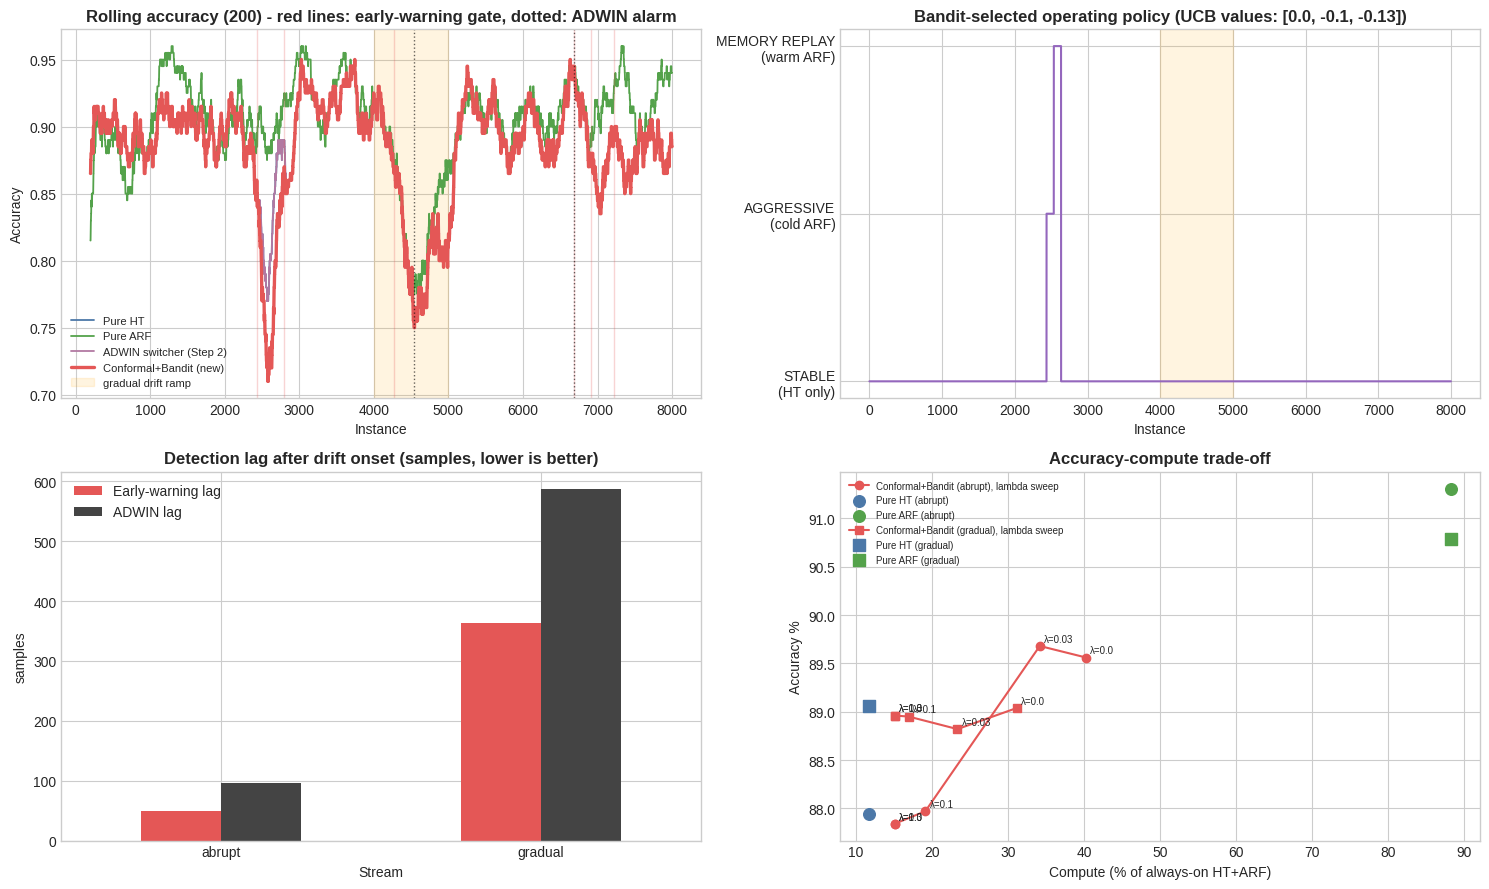

In [15]:
#@title Step 11 — Visual summary
import numpy as np
import matplotlib.pyplot as plt

def roll(c, w=200):
    return np.convolve(c, np.ones(w) / w, mode='valid')

kind = 'gradual'
ctrl, data = keep[kind]
fig, ax = plt.subplots(2, 2, figsize=(15, 9))

# (a) rolling accuracy + early-warning gates + ADWIN alarms
colors = {'Pure HT': '#4c78a8', 'Pure ARF': '#54a24b', 'ADWIN switcher (Step 2)': '#b279a2', 'Conformal+Bandit (new)': '#e45756'}
for name, col in colors.items():
    if (kind, name) in keep:
        ax[0, 0].plot(np.arange(199, 8000), roll(keep[(kind, name)]), label=name, color=col,
                      lw=2.4 if 'new' in name else 1.3)
ax[0, 0].axvspan(4000, 5000, color='orange', alpha=0.12, label='gradual drift ramp')
for t, _ in ctrl.gate_log:
    ax[0, 0].axvline(t, color='#e45756', alpha=0.25, lw=1)
for t in ctrl.adwin_alarms:
    ax[0, 0].axvline(t, color='black', ls=':', alpha=0.6, lw=1)
ax[0, 0].set_title("Rolling accuracy (200) - red lines: early-warning gate, dotted: ADWIN alarm", fontweight='bold')
ax[0, 0].set_xlabel("Instance"); ax[0, 0].set_ylabel("Accuracy"); ax[0, 0].legend(loc='lower left', fontsize=8)

# (b) policy timeline
steps = np.zeros(8000); cur = 'STABLE_LOW_COST'; pl = ctrl.policy_log + [(8000, None)]
level = {'STABLE_LOW_COST': 0, 'AGGRESSIVE_DRIFT_RECOVERY': 1, 'MEMORY_REPLAY': 2}
for (t0, p), (t1, _) in zip([(0, 'STABLE_LOW_COST')] + pl[:-1], pl):
    steps[t0:t1] = level[p]
closes = [t for t, _ in ctrl.gate_log]
ax[0, 1].step(np.arange(8000), steps, color='tab:purple', where='post')
ax[0, 1].set_yticks([0, 1, 2]); ax[0, 1].set_yticklabels(['STABLE\n(HT only)', 'AGGRESSIVE\n(cold ARF)', 'MEMORY REPLAY\n(warm ARF)'])
ax[0, 1].axvspan(4000, 5000, color='orange', alpha=0.12)
ax[0, 1].set_title(f"Bandit-selected operating policy (UCB values: {np.round(ctrl.bandit.val, 3).tolist()})", fontweight='bold')
ax[0, 1].set_xlabel("Instance")

# (c) lead over ADWIN
d = detection[detection.Stream.isin(['abrupt', 'gradual'])].groupby('Stream')[['Early-warning lag', 'ADWIN lag']].mean()
d.plot.bar(ax=ax[1, 0], color=['#e45756', '#444444'], rot=0)
ax[1, 0].set_title("Detection lag after drift onset (samples, lower is better)", fontweight='bold'); ax[1, 0].set_ylabel("samples")

# (d) Pareto: accuracy vs compute
for stream, mk in [('abrupt', 'o'), ('gradual', 's')]:
    s = sweep[sweep.Stream == stream]
    ax[1, 1].plot(s['Compute units'] / 68000 * 100, s['Accuracy %'], marker=mk, color='#e45756', label=f'Conformal+Bandit ({stream}), lambda sweep')
    for _, r in s.iterrows():
        ax[1, 1].annotate(f"λ={r['lambda']}", (r['Compute units'] / 68000 * 100, r['Accuracy %']), fontsize=7, xytext=(3, 3), textcoords='offset points')
    for m, c in [('Pure HT', '#4c78a8'), ('Pure ARF', '#54a24b')]:
        q = results[(results.Stream == stream) & (results.Model == m)]
        ax[1, 1].scatter(q['Cost vs shadow %'].mean(), q['Accuracy %'].mean(), color=c, marker=mk, s=70, label=f'{m} ({stream})')
ax[1, 1].set_xlabel("Compute (% of always-on HT+ARF)"); ax[1, 1].set_ylabel("Accuracy %")
ax[1, 1].set_title("Accuracy-compute trade-off", fontweight='bold'); ax[1, 1].legend(fontsize=7)

plt.tight_layout(); plt.savefig('step11_objectives_summary.png', dpi=200); plt.show()


Real stream: 100,000 samples, 95 cycles, positive rate 23.7%, T_hi = 27.7 C


,Accuracy %,Late-life acc % (2nd half),Compute % of always-on,ARF active %,Gate openings
Model,,,,,
Pure HT,98.26,99.54,11.76,NaN,NaN
Pure ARF,98.46,98.27,88.24,NaN,NaN
ADWIN switcher (Step 2),98.27,99.54,11.80,NaN,NaN
Conformal+Bandit (new),98.76,99.43,32.15,13.65,125.0


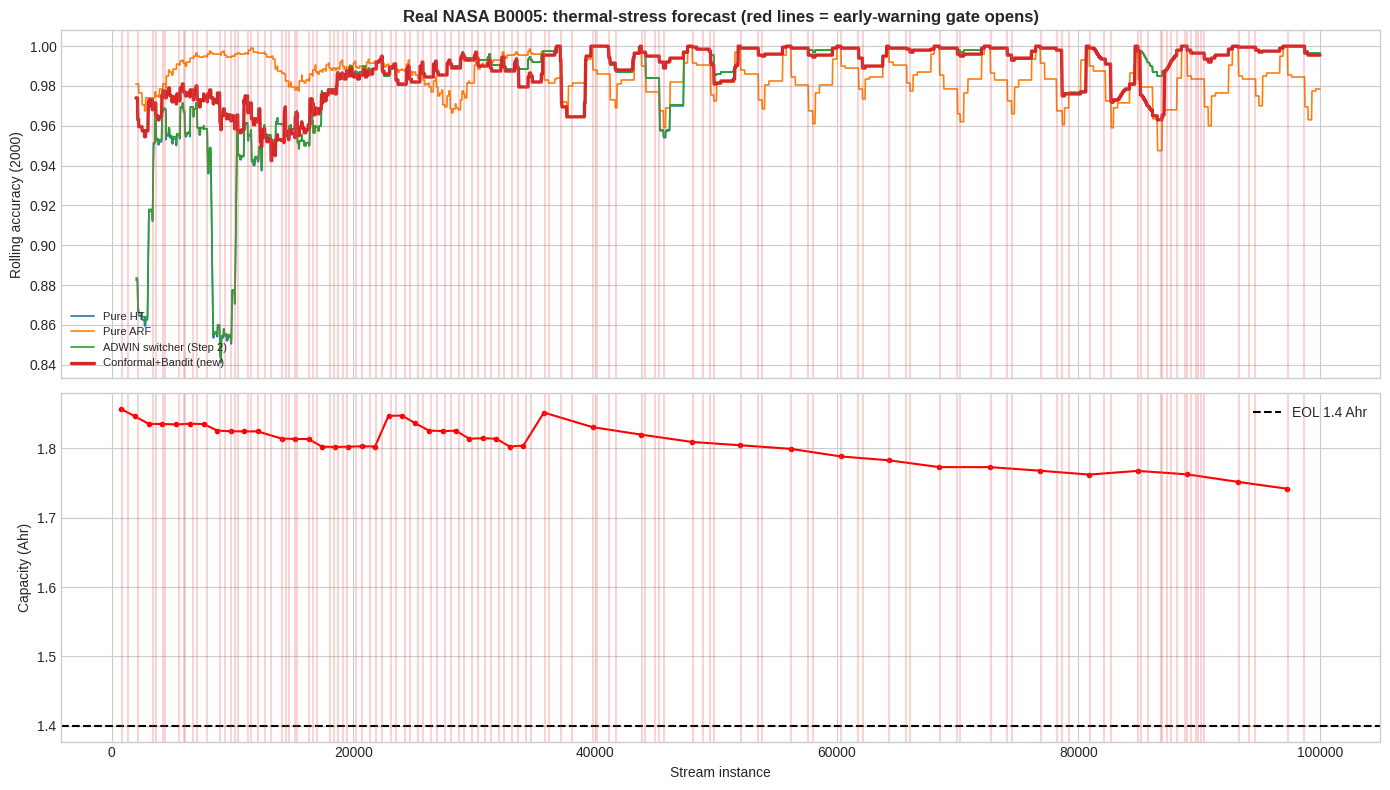


=== Verdict on real data (computed, not hand-written) ===
Accuracy      : new 98.76%  | HT 98.26%  | ARF 98.46%
Late-life acc : new 99.43%  | HT 99.54%  | ARF 98.27%
Compute       : new 32.1% of always-on  | ARF alone 88.2%  (ARF on 13.7% of the time)
Share of the HT->ARF accuracy gap recovered: 250%
First early-warning gate: instance 809 (cycle 1, capacity about 1.86 Ahr); 125 gate openings in total, first signal = noise>P90
WINS  : more accurate than the plain Hoeffding Tree; within 1 point of the ARF at much lower compute


In [16]:
#@title Step 12 — Real NASA B0005 battery evaluation (needs `df` and `df_capacity` from the data-parsing cell)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print

def build_real_task(df, horizon=50, quantile=0.80):
    """
    Thermal-stress forecast on REAL telemetry.
    Features : V, I, T, dV, dT, Power, Op (1 = charge, 0 = discharge)
    Label    : 1 if the cell temperature reaches its own 80th-percentile level within the next `horizon` samples
               of the same cycle.  How voltage / current predict that heating changes as the cell ages, so the
               concept drifts GRADUALLY with real capacity fade (no hand-made drift anywhere).
    Note     : the label depends on the next `horizon` samples, so in deployment it arrives with that delay.
    """
    d = df.copy()
    t_hi = d['Temperature'].quantile(quantile)
    fut = d.groupby('Cycle')['Temperature'].transform(lambda s: s[::-1].rolling(horizon, min_periods=1).max()[::-1])
    d['Op'] = (d['Operation'] == 'charge').astype(int)
    d['Target'] = (fut >= t_hi).astype(int)
    cols = ['Voltage', 'Current', 'Temperature', 'Delta_Voltage', 'Delta_Temp', 'Power', 'Op']
    return d, cols, t_hi

def run_real_battery(df, df_capacity, max_samples=100000, horizon=50, window=2000):
    d, cols, t_hi = build_real_task(df.iloc[:max_samples], horizon)
    xs, ys = d[cols].to_dict(orient='records'), d['Target'].astype(int).tolist()
    data, n = list(zip(xs, ys)), len(ys)
    print(f"Real stream: {n:,} samples, {d['Cycle'].nunique()} cycles, positive rate {np.mean(ys):.1%}, T_hi = {t_hi:.1f} C")

    models = {'Pure HT': lambda: PureHT(42), 'Pure ARF': lambda: PureARF(seed=42)}
    if 'SmartMetaController' in globals():
        models['ADWIN switcher (Step 2)'] = lambda: ADWINSwitcher(42)
    models['Conformal+Bandit (new)'] = lambda: ConformalBanditController(seed=42)

    rows, curves, ctrl = [], {}, None
    always_on = n * (1.0 + 5 * 1.5)                      # compute of HT + 5-tree ARF on every sample
    half = n // 2
    for name, mk in models.items():
        m = mk(); r, c = run_prequential(m, data)
        r2 = {'Model': name, 'Accuracy %': r['Accuracy %'], 'Late-life acc % (2nd half)': 100 * c[half:].mean(),
              'Compute % of always-on': 100 * r['Compute units'] / always_on}
        if isinstance(m, ConformalBanditController):
            r2['ARF active %'] = 100 * m.arf_active_steps / n; r2['Gate openings'] = len(m.gate_log); ctrl = m
        rows.append(r2); curves[name] = c
    res = pd.DataFrame(rows).set_index('Model').round(2)
    display(res)

    # ---- plot: accuracy over the cell's life, gate openings, capacity fade ----
    first_idx = d.reset_index(drop=True).groupby('Cycle').head(1).index.values
    cyc_start = dict(zip(d['Cycle'].unique(), first_idx))
    fig, ax = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
    for name, c in curves.items():
        ax[0].plot(np.arange(window - 1, n), np.convolve(c, np.ones(window) / window, mode='valid'), label=name,
                   lw=2.4 if 'new' in name else 1.2)
    for t, _ in ctrl.gate_log:
        ax[0].axvline(t, color='#e45756', alpha=0.25)
    ax[0].set_ylabel(f"Rolling accuracy ({window})"); ax[0].legend(loc='lower left', fontsize=8)
    ax[0].set_title("Real NASA B0005: thermal-stress forecast (red lines = early-warning gate opens)", fontweight='bold')
    cap = df_capacity[df_capacity['Cycle'].isin(cyc_start)]
    ax[1].plot([cyc_start[c] for c in cap['Cycle']], cap['Capacity'], 'r.-')
    ax[1].axhline(1.4, color='black', ls='--', label='EOL 1.4 Ahr')
    for t, _ in ctrl.gate_log:
        ax[1].axvline(t, color='#e45756', alpha=0.25)
    ax[1].set_ylabel("Capacity (Ahr)"); ax[1].set_xlabel("Stream instance"); ax[1].legend()
    plt.tight_layout(); plt.savefig('step12_real_battery.png', dpi=200); plt.show()

    # ---- self-generated verdict: wins and losses vs the baselines, from the numbers above ----
    new, ht, arf = res.loc['Conformal+Bandit (new)'], res.loc['Pure HT'], res.loc['Pure ARF']
    print("\n=== Verdict on real data (computed, not hand-written) ===")
    print(f"Accuracy      : new {new['Accuracy %']:.2f}%  | HT {ht['Accuracy %']:.2f}%  | ARF {arf['Accuracy %']:.2f}%")
    print(f"Late-life acc : new {new['Late-life acc % (2nd half)']:.2f}%  | HT {ht['Late-life acc % (2nd half)']:.2f}%  | ARF {arf['Late-life acc % (2nd half)']:.2f}%")
    print(f"Compute       : new {new['Compute % of always-on']:.1f}% of always-on  | ARF alone {arf['Compute % of always-on']:.1f}%  (ARF on {new['ARF active %']:.1f}% of the time)")
    gap = arf['Accuracy %'] - ht['Accuracy %']
    if gap > 0.1:
        print(f"Share of the HT->ARF accuracy gap recovered: {100 * (new['Accuracy %'] - ht['Accuracy %']) / gap:.0f}%")
    else:
        print("ARF does not beat HT here, so there is no accuracy gap for the controller to recover.")
    if ctrl.gate_log:
        t0 = ctrl.gate_log[0][0]; c0 = int(d['Cycle'].iloc[t0])
        prev = df_capacity[df_capacity['Cycle'] <= c0]
        cap0 = f"{prev['Capacity'].iloc[-1]:.2f} Ahr" if len(prev) else "n/a"
        print(f"First early-warning gate: instance {t0:,} (cycle {c0}, capacity about {cap0}); "
              f"{len(ctrl.gate_log)} gate openings in total, first signal = {ctrl.gate_log[0][1]}")
    wins = []
    if new['Accuracy %'] > ht['Accuracy %'] + 0.1:                wins.append("more accurate than the plain Hoeffding Tree")
    if new['Compute % of always-on'] < arf['Compute % of always-on'] - 20 and new['Accuracy %'] >= arf['Accuracy %'] - 1.0:
        wins.append("within 1 point of the ARF at much lower compute")
    print("WINS  :", "; ".join(wins) if wins else "none by these criteria")
    if new['Accuracy %'] < ht['Accuracy %'] - 0.1:
        print("LOSS  : less accurate than the plain Hoeffding Tree")
    return res, curves, ctrl

if 'df' in globals() and 'df_capacity' in globals() and {'Cycle', 'Operation', 'Voltage', 'Current', 'Temperature',
                                                          'Delta_Voltage', 'Delta_Temp', 'Power'} <= set(df.columns):
    real_results, real_curves, real_ctrl = run_real_battery(df, df_capacity)
else:
    print("Skipped: run the data-parsing cell first so that `df` and `df_capacity` exist.")
